# Лабораторная №2. Подробный разбор

Этот ноутбук объясняет рабочую версию `../lr2_credit_score_eda.ipynb`. В нём те же расчётные ячейки ЛР2, таблицы и графики, но с подробным разбором каждой операции и смысла результатов. Объяснения рассчитаны на чтение без предварительного знакомства со статистикой и pandas.

Рабочая версия – краткая лабораторная; здесь можно выяснить, почему выбран именно такой способ расчёта и как объяснить его на защите.

Ноутбук запускается из папки `eda-visualization/docs`. Входная таблица – результат ЛР1 `../../dataset-intro/credit_score_train_clean.csv`, готовые таблицы сохраняются в общую папку `../results`.

Ячейки выполняются по порядку: поздние используют переменные предыдущих. Например, `results` из раздела 15 нужен для подписей категориальных графиков и итоговой таблицы гипотез.

## 0. Что исследуем и откуда взялись данные

Credit Score Classification – учебный набор с Kaggle: помесячные финансовые сведения о клиентах банка.
В `train.csv` 100 000 строк: 12 500 клиентов, у каждого ровно 8 месяцев (январь–август).
Одна строка – **клиент в конкретном месяце**, а не клиент целиком. Это главное, что нужно помнить
при любых расчётах: один и тот же человек встречается в таблице восемь раз.

Целевая переменная `Credit_Score` принимает три значения: `Good` (хороший), `Standard` (средний),
`Poor` (плохой). Это **порядковая** категория: `Poor` < `Standard` < `Good`, но расстояние между
классами не измерено в числах. Поэтому для неё подходят ранговые методы, а не среднее.

В ЛР1 таблица уже очищена: технические маркеры (`_`, `!@9#%8`) заменены, невозможные значения
(возраст −500, ставка 5 797%) признаны пропусками и восстановлены по тому же клиенту, добавлены
доли нагрузки (`Debt_to_Annual_Income`, `EMI_to_Monthly_Income`, `Investment_to_Monthly_Income`)
и категории `Age_Group`, `Delay_Band`. Пропусков в таблице нет.

Валюта в наборе не указана, поэтому все деньги подписаны как «у.е.» (условные единицы).
Данные, судя по ступенчатым распределениям, частично синтетические – это ограничение для
любых выводов о реальных клиентах.

## 1. Загрузка, настройки и общие обозначения

`import numpy as np`, `import pandas as pd` подключают работу с массивами и таблицами,
`matplotlib.pyplot` и `seaborn` – графики, `from scipy import stats` – статистические тесты.

`pd.set_option("display.float_format", ...)` меняет только **отображение** чисел: три знака
после запятой и разделитель тысяч. Значения в таблице не округляются.

`sns.set_theme(style="whitegrid")` задаёт единый стиль всем графикам: белый фон и сетку.
`SCORE_ORDER = ["Good", "Standard", "Poor"]` фиксирует порядок классов на всех рисунках,
а `SCORE_COLORS` – их цвета: зелёный, синий, красный. Это требование «единого стиля» из задания:
один и тот же класс везде одного цвета.

`LABELS` – словарь подписей осей с единицами измерения. Функция `label(column)` возвращает подпись
или само имя столбца, если подписи нет. Так подписи не приходится дублировать в каждом графике.

`pd.read_csv` читает очищенную таблицу ЛР1. Путь относительный: `../..` поднимает из
`eda-visualization/docs` в корень курса, оттуда – в `dataset-intro`. В основном ноутбуке вместо этого
продолжается таблица `train_clean`, полученная в первой части; содержимое одинаковое.

`pd.Categorical(..., ordered=True)` превращает `Credit_Score` в упорядоченную категорию:
pandas будет знать, что `Good` идёт раньше `Standard`. `Score_Rank` – та же цель числом:
`Poor` = 0, `Standard` = 1, `Good` = 2. Число нужно, чтобы посчитать корреляцию с рейтингом.
Чем больше `Score_Rank`, тем лучше рейтинг – это важно для чтения знаков корреляций.

`NUMERIC` – 20 числовых признаков, `CATEGORICAL` – 4 категориальных. Списки заданы явно:
`ID`, `Customer_ID`, `Month` – идентификаторы, а не характеристики клиента, и в анализ не входят.
`RESULTS` – папка для итоговых таблиц.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"

BASE_COLOR = "#4c78a8"
ACCENT_COLOR = "#f58518"
SCORE_ORDER = ["Good", "Standard", "Poor"]
SCORE_COLORS = {"Good": "#4c956c", "Standard": "#4c78a8", "Poor": "#d1495b"}
SCORE_PALETTE = [SCORE_COLORS[s] for s in SCORE_ORDER]
SCORE_RU = {"Good": "Good (хороший)", "Standard": "Standard (средний)", "Poor": "Poor (плохой)"}

LABELS = {
    "Age": "Возраст, лет",
    "Annual_Income": "Годовой доход, у.е.",
    "Monthly_Inhand_Salary": "Месячный доход на руки, у.е.",
    "Num_Bank_Accounts": "Число банковских счетов, шт.",
    "Num_Credit_Card": "Число кредитных карт, шт.",
    "Interest_Rate": "Процентная ставка, %",
    "Num_of_Loan": "Число кредитов, шт.",
    "Delay_from_due_date": "Просрочка платежа, дней",
    "Num_of_Delayed_Payment": "Число просроченных платежей, шт.",
    "Changed_Credit_Limit": "Изменение кредитного лимита, %",
    "Num_Credit_Inquiries": "Число кредитных запросов, шт.",
    "Outstanding_Debt": "Непогашенный долг, у.е.",
    "Credit_Utilization_Ratio": "Использование лимита, %",
    "Total_EMI_per_month": "Ежемесячный платёж EMI, у.е.",
    "Amount_invested_monthly": "Инвестиции в месяц, у.е.",
    "Monthly_Balance": "Остаток на конец месяца, у.е.",
    "Credit_History_Months": "Длительность кредитной истории, мес.",
    "Debt_to_Annual_Income": "Долг / годовой доход, доля",
    "EMI_to_Monthly_Income": "EMI / месячный доход, доля",
    "Investment_to_Monthly_Income": "Инвестиции / месячный доход, доля",
    "Credit_Score": "Кредитный рейтинг",
}

def label(column):
    return LABELS.get(column, column)

from pathlib import Path

df = pd.read_csv("../../dataset-intro/credit_score_train_clean.csv")
df["Credit_Score"] = pd.Categorical(df["Credit_Score"], categories=SCORE_ORDER, ordered=True)
# Порядковая кодировка цели для ранговых корреляций: чем больше, тем лучше рейтинг.
df["Score_Rank"] = df["Credit_Score"].map({"Poor": 0, "Standard": 1, "Good": 2}).astype(int)

NUMERIC = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts", "Num_Credit_Card",
    "Interest_Rate", "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment",
    "Changed_Credit_Limit", "Num_Credit_Inquiries", "Outstanding_Debt",
    "Credit_Utilization_Ratio", "Total_EMI_per_month", "Amount_invested_monthly",
    "Monthly_Balance", "Credit_History_Months", "Debt_to_Annual_Income",
    "EMI_to_Monthly_Income", "Investment_to_Monthly_Income",
]
CATEGORICAL = ["Occupation", "Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour"]
RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

print("Размер:", df.shape, "| клиентов:", df["Customer_ID"].nunique())

Размер: (100000, 33) | клиентов: 12500


### Что видно в результате загрузки

100 000 строк и 33 столбца (32 из ЛР1 плюс `Score_Rank`), 12 500 клиентов.
Пропусков после ЛР1 нет, поэтому дальше не нужно отдельно отбрасывать `NaN`.

## 2. Срез «один клиент – одна строка»

Каждый клиент встречается 8 раз, а его стабильные признаки (возраст, доход, ставка, долг)
в ЛР1 восстановлены одинаковыми во всех месяцах. Если подать в статистический тест все 100 000 строк,
тест «увидит» 100 000 независимых наблюдений, хотя на самом деле их 12 500. Это называется
**псевдорепликацией**: p-значения получаются заниженными, и даже случайные различия выглядят значимыми.

`df[df["Month_Number"] == 8]` оставляет только август – последний месяц с известной целью.
`.copy()` создаёт отдельную таблицу, чтобы последующие изменения не затронули `df`.

`value_counts(normalize=True)` считает доли классов, `reindex(SCORE_ORDER)` упорядочивает их,
`mul(100)` переводит в проценты.

Правило дальше: **графики распределений** строим по всем строкам (это просто описание данных),
а **тесты, корреляции и сравнения классов** – по срезу.

In [2]:
snapshot = df[df["Month_Number"] == 8].copy()
print("Срез (август):", snapshot.shape, "| уникальных клиентов:", snapshot["Customer_ID"].nunique())
snapshot["Credit_Score"].value_counts(normalize=True).reindex(SCORE_ORDER).mul(100).round(2).to_frame("доля, %")

Срез (август): (12500, 33) | уникальных клиентов: 12500


,"доля, %"
Credit_Score,
Good,19.300
Standard,51.880
Poor,28.820


### Что видно

В срезе 12 500 строк и столько же уникальных клиентов – каждый клиент ровно один раз.
Баланс классов в августе: `Good` 19,3%, `Standard` 51,9%, `Poor` 28,8%. Он близок к балансу всей
таблицы (17,8 / 53,2 / 29,0%), значит срез не искажает структуру цели.

Почему именно август, а не случайный месяц? Это самое свежее состояние клиента. Можно было бы
взять любой месяц: в разделе 3.2 видно, что признаки по месяцам почти не меняются.

## 3. Основные числовые характеристики

`df[NUMERIC].agg([...])` применяет к каждому столбцу перечисленные функции:

- `count` – количество непустых значений;
- `mean` – среднее арифметическое;
- `median` – середина отсортированного ряда: половина значений меньше, половина больше;
- `std` – стандартное отклонение, разброс вокруг среднего в единицах признака;
- `min`, `max` – наименьшее и наибольшее значение;
- `skew` – асимметрия: 0 у симметричного распределения, > 0 – длинный хвост вправо.

`.T` транспонирует таблицу: признаки становятся строками, характеристики – столбцами.
`rename(columns=...)` переводит названия характеристик на русский.

In [3]:
descriptive = df[NUMERIC].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T
descriptive = descriptive.rename(columns={
    "count": "Наблюдений", "mean": "Среднее", "median": "Медиана",
    "std": "Станд. отклонение", "min": "Минимум", "max": "Максимум", "skew": "Асимметрия",
})
descriptive.round(3)

,Наблюдений,Среднее,Медиана,Станд. отклонение,Минимум,Максимум,Асимметрия
Age,"100,000.000",33.310,33.000,10.765,14.000,56.000,0.157
Annual_Income,"100,000.000","50,505.123","36,999.705","38,299.422","7,005.930","179,987.280",1.130
Monthly_Inhand_Salary,"100,000.000","4,198.390","3,094.825","3,187.570",303.645,"15,204.633",1.129
Num_Bank_Accounts,"100,000.000",5.369,5.000,2.593,0.000,10.000,-0.189
Num_Credit_Card,"100,000.000",5.534,5.000,2.067,0.000,11.000,0.226
Interest_Rate,"100,000.000",14.532,13.000,8.741,1.000,34.000,0.496
Num_of_Loan,"100,000.000",3.533,3.000,2.446,0.000,9.000,0.446
Delay_from_due_date,"100,000.000",21.082,18.000,14.840,0.000,67.000,0.974
Num_of_Delayed_Payment,"100,000.000",13.339,14.000,6.305,0.000,98.000,-0.055
Changed_Credit_Limit,"100,000.000",10.389,9.400,6.783,-6.490,36.970,0.642


### Почему среднее и медиана отличаются

У долга среднее 1 426 у.е., медиана 1 166 у.е.; у платежа EMI среднее 117 у.е., медиана 66 у.е.
Несколько очень больших значений тянут среднее вверх, а на медиану почти не влияют.
Пример: у ряда `[1, 1, 2, 2, 9]` медиана 2, а среднее 3. Поэтому дальше классы сравниваются по медианам.

У возраста, использования лимита и длительности истории асимметрия близка к нулю (|skew| < 0,2):
среднее и медиана почти совпадают. Максимальная асимметрия – у `Total_EMI_per_month` (≈ 27).

## 4. Гистограммы

Гистограмма делит диапазон значений на интервалы и показывает, сколько наблюдений попало в каждый.
По вертикали – число наблюдений (клиенто-месяцев), по горизонтали – значение признака.

`plt.subplots(3, 4)` создаёт сетку из 12 графиков; `zip(axes.flat, HIST_FEATURES)` ставит
в пару каждому графику свой признак.

Для `Total_EMI_per_month` значения выше 99-го перцентиля (`quantile(0.99)`) не рисуются:
единичные значения до 16 000 у.е. сжали бы основную массу в один столбик. Данные при этом не удаляются –
это только масштаб рисунка.

`discrete` – признак целочисленный и с небольшим числом уникальных значений (число счетов, ставка).
Для таких признаков `sns.histplot(discrete=True)` рисует отдельный столбик на каждое целое значение,
а сглаженная кривая плотности `kde` не строится: она изображала бы значения между целыми числами,
которых не бывает.

Оранжевая пунктирная линия – медиана, чёрная точечная – среднее. Если они разошлись,
у распределения есть хвост.

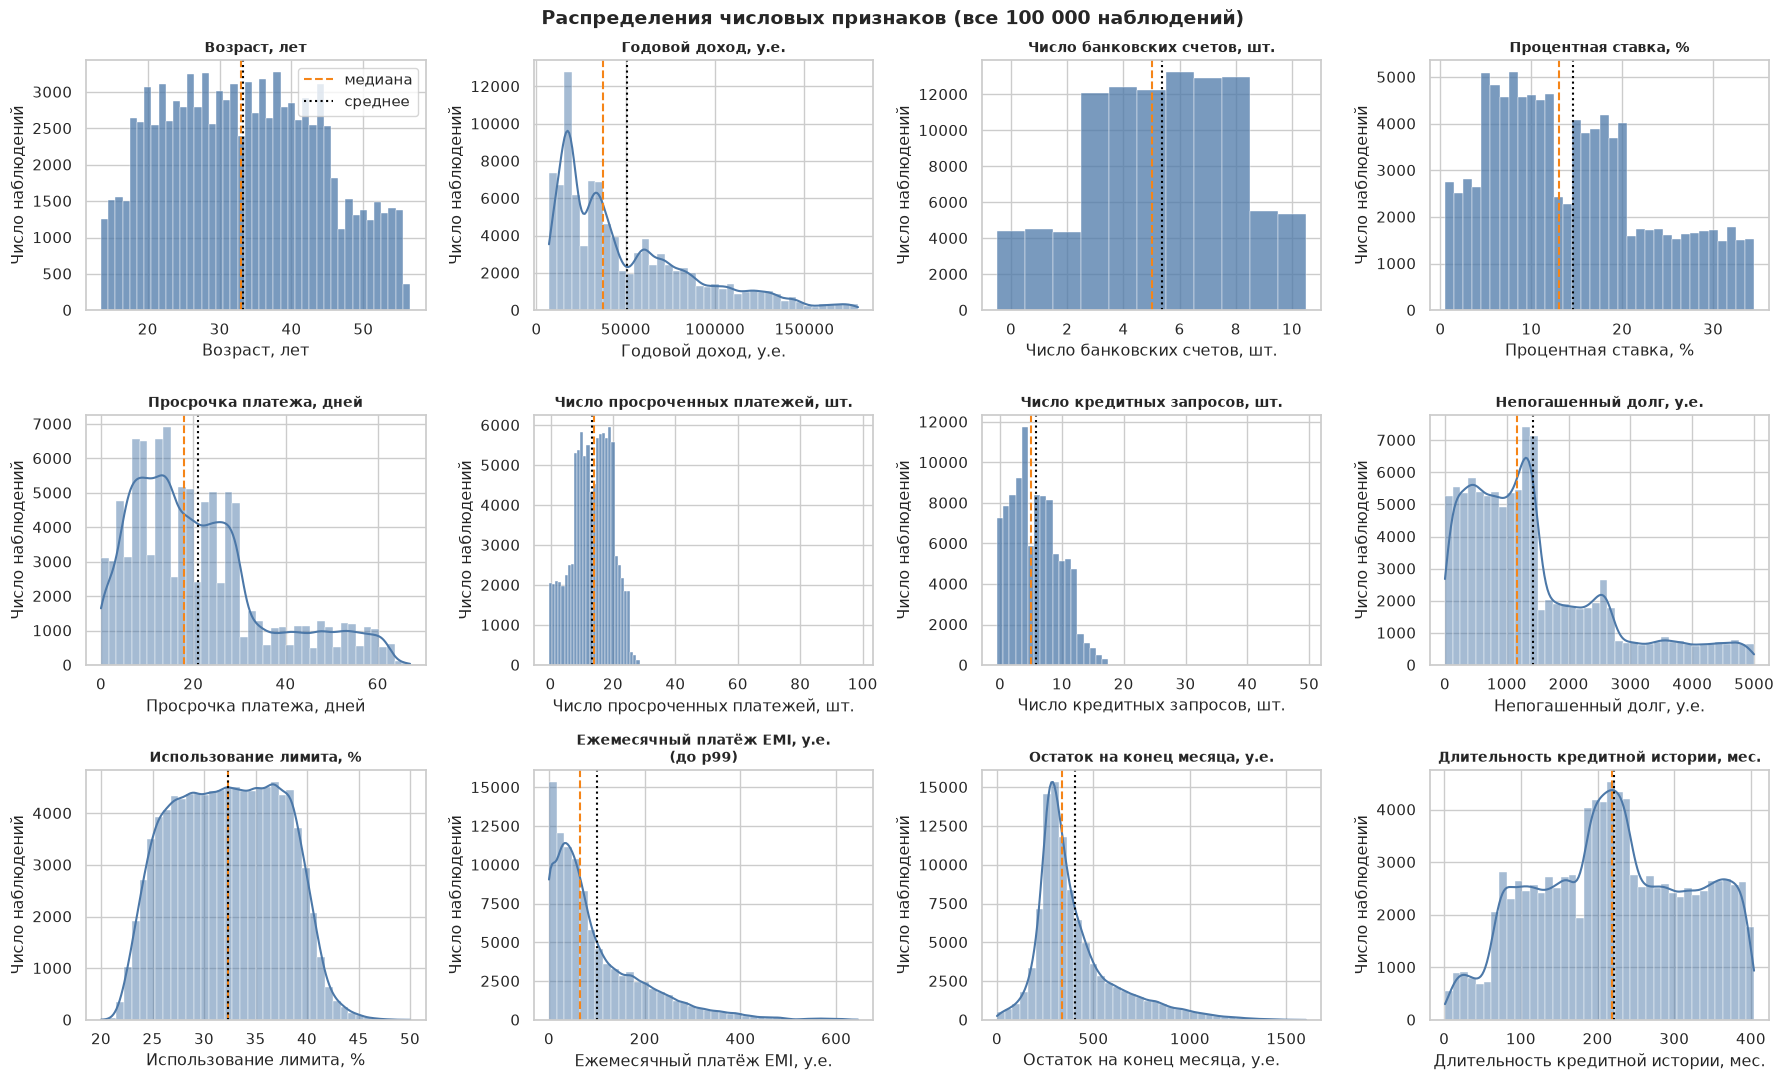

In [4]:
HIST_FEATURES = [
    "Age", "Annual_Income", "Num_Bank_Accounts", "Interest_Rate",
    "Delay_from_due_date", "Num_of_Delayed_Payment", "Num_Credit_Inquiries", "Outstanding_Debt",
    "Credit_Utilization_Ratio", "Total_EMI_per_month", "Monthly_Balance", "Credit_History_Months",
]
CLIP_AT_P99 = {"Total_EMI_per_month", "EMI_to_Monthly_Income", "Amount_invested_monthly"}

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, column in zip(axes.flat, HIST_FEATURES):
    values = df[column]
    title = label(column)
    if column in CLIP_AT_P99:
        values = values[values <= values.quantile(0.99)]
        title += "\n(до p99)"
    discrete = df[column].dtype.kind == "i" and df[column].nunique() <= 60
    sns.histplot(values, ax=ax, color=BASE_COLOR, kde=not discrete, discrete=discrete,
                 bins="auto" if discrete else 40, edgecolor="white", linewidth=0.3)
    ax.axvline(values.median(), color=ACCENT_COLOR, linestyle="--", linewidth=1.5, label="медиана")
    ax.axvline(values.mean(), color="black", linestyle=":", linewidth=1.5, label="среднее")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(label(column))
    ax.set_ylabel("Число наблюдений")
axes.flat[0].legend(loc="upper right")
fig.suptitle("Распределения числовых признаков (все 100 000 наблюдений)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Что видно на гистограммах

- Возраст, использование лимита и длительность истории – плоские, почти равномерные распределения без пика.
- Доход, долг, остаток – высокий столбец слева и длинный хвост вправо; среднее правее медианы.
- Ставка и число счетов имеют «ступеньки» и провалы (например, около 13% и 17% ставки). Для реальных
  данных это необычно и указывает на синтетическую генерацию набора.

## 5. Проверка нормальности: асимметрия, эксцесс и тест

Многие классические методы (t-тест, ANOVA, корреляция Пирсона) предполагают нормальное распределение.
Проверяем, можно ли их применять.

- **Асимметрия** (`skew`) – перекос: 0 у нормального распределения.
- **Эксцесс** (`kurt`, excess kurtosis) – «островершинность» относительно нормального: 0 у нормального,
  отрицательный – плоская вершина, положительный – острый пик и тяжёлые хвосты.
- **Тест Д'Агостино–Пирсона** `stats.normaltest` объединяет асимметрию и эксцесс в одну статистику K².
  Нулевая гипотеза H₀: распределение нормальное. Если p-value < 0,05, H₀ отвергается.

Тест Шапиро–Уилка не используем: при n > 5 000 SciPy предупреждает, что его p-значение неточно.

Цикл `for column in NUMERIC` для каждого признака считает характеристики и собирает их в список словарей,
`pd.DataFrame(...)` превращает список в таблицу. `.style.format` задаёт формат вывода,
`background_gradient` раскрашивает столбец асимметрии: красный – правый хвост, синий – левый.

In [5]:
normality = []
for column in NUMERIC:
    values = snapshot[column]
    k2, p_value = stats.normaltest(values)
    skew = values.skew()
    normality.append({
        "признак": column,
        "среднее": values.mean(),
        "медиана": values.median(),
        "асимметрия": skew,
        "эксцесс": values.kurt(),
        "K² Д'Агостино": k2,
        "p-value": p_value,
        "нормально (α=0.05)": "да" if p_value > 0.05 else "нет",
        "форма": ("≈ симметричное" if abs(skew) < 0.5
                  else "умеренная правая асимм." if 0.5 <= skew < 1
                  else "сильная правая асимм." if skew >= 1
                  else "левая асимметрия"),
    })
normality = pd.DataFrame(normality).set_index("признак")
normality.style.format({
    "среднее": "{:,.2f}", "медиана": "{:,.2f}", "асимметрия": "{:.2f}", "эксцесс": "{:.2f}",
    "K² Д'Агостино": "{:,.1f}", "p-value": "{:.1e}",
}).background_gradient(subset=["асимметрия"], cmap="RdBu_r", vmin=-3, vmax=3)

,среднее,медиана,асимметрия,эксцесс,K² Д'Агостино,p-value,нормально (α=0.05),форма
признак,,,,,,,,
Age,33.31,33.00,0.16,-0.93,"2,003.6",0.0e+00,нет,≈ симметричное
Annual_Income,"50,505.12","36,999.71",1.13,0.61,"1,889.1",0.0e+00,нет,сильная правая асимм.
Monthly_Inhand_Salary,"4,198.39","3,094.83",1.13,0.62,"1,890.5",0.0e+00,нет,сильная правая асимм.
Num_Bank_Accounts,5.37,5.00,-0.19,-0.69,712.4,2.0e-155,нет,≈ симметричное
Num_Credit_Card,5.53,5.00,0.23,-0.33,183.8,1.2e-40,нет,≈ симметричное
Interest_Rate,14.53,13.00,0.50,-0.68,"1,064.4",7.3e-232,нет,≈ симметричное
Num_of_Loan,3.53,3.00,0.45,-0.61,812.9,3.0e-177,нет,≈ симметричное
Delay_from_due_date,21.08,18.00,0.98,0.36,"1,475.7",0.0e+00,нет,умеренная правая асимм.
Num_of_Delayed_Payment,13.34,14.00,-0.04,0.90,212.3,7.9e-47,нет,≈ симметричное


### Что видно

У всех 20 признаков p-value практически равно нулю: ни один не распределён нормально.

Важная оговорка: при n = 12 500 тест очень чувствителен и отвергает нормальность даже при
небольших отклонениях. Поэтому одного p-value мало – смотрим ещё на форму (асимметрия, эксцесс)
и на Q-Q-графики. Например, у возраста асимметрия 0,16, но эксцесс −0,93: распределение
симметричное, но плоское, а не колоколообразное.

Вывод для дальнейшей работы: используем **непараметрические** методы – медианы,
корреляцию Спирмена, критерий Краскела–Уоллиса.

## 6. Q-Q-графики

Q-Q-график (quantile–quantile) сравнивает квантили выборки с квантилями нормального распределения.
`stats.probplot` сортирует значения выборки и ставит каждому в пару теоретическое значение
стандартного нормального распределения; заодно возвращает прямую, по которой лежали бы точки,
если бы распределение было нормальным.

Как читать: точки на прямой – распределение похоже на нормальное.
S-образная кривая – хвосты короче нормальных (плоское распределение).
Точки, задирающиеся вверх справа, – длинный правый хвост.

Выбраны четыре характерных признака: два плоских (возраст, использование лимита)
и два с хвостом (долг, EMI).

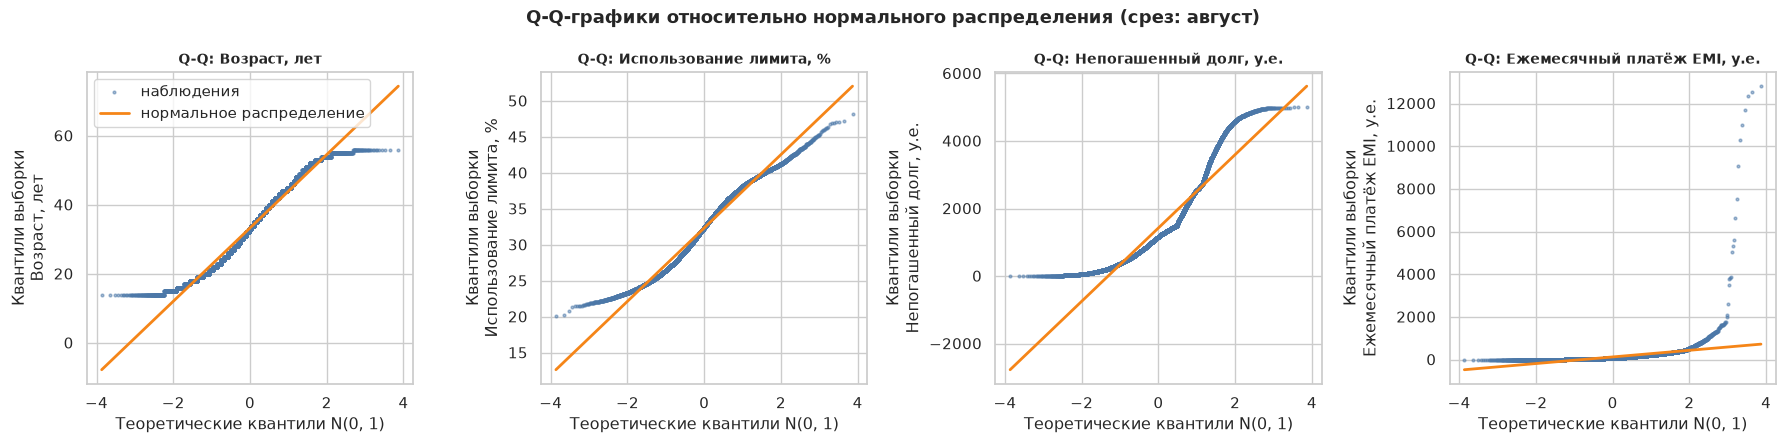

In [6]:
QQ_FEATURES = ["Age", "Credit_Utilization_Ratio", "Outstanding_Debt", "Total_EMI_per_month"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, column in zip(axes, QQ_FEATURES):
    (theoretical, ordered), (slope, intercept, _) = stats.probplot(snapshot[column], dist="norm")
    ax.scatter(theoretical, ordered, s=4, color=BASE_COLOR, alpha=0.5, label="наблюдения")
    ax.plot(theoretical, slope * theoretical + intercept, color=ACCENT_COLOR, linewidth=2,
            label="нормальное распределение")
    ax.set_title(f"Q-Q: {label(column)}", fontsize=10)
    ax.set_xlabel("Теоретические квантили N(0, 1)")
    ax.set_ylabel(f"Квантили выборки\n{label(column)}")
axes[0].legend(loc="upper left")
fig.suptitle("Q-Q-графики относительно нормального распределения (срез: август)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### Что видно

- Возраст и использование лимита – S-образная форма: по краям меньше значений, чем у нормального.
- Долг – точки уходят вверх справа: правый хвост.
- EMI – почти горизонтальная линия и резкий подъём в самом конце: основная масса маленькая,
  а единичные значения на порядки больше. Это самое далёкое от нормального распределение в наборе.

## 7. Логарифмирование

Денежные величины часто распределены логнормально: если взять логарифм, распределение становится
близким к симметричному. `np.log1p(x)` считает `ln(1 + x)`; единица добавляется, чтобы нулевые
значения (например, нулевой EMI) не давали минус бесконечность.

Таблица сравнивает асимметрию до и после преобразования; график показывает долг в обеих шкалах.
Это не изменение данных, а проверка: поможет ли логарифм линейной модели в ЛР3.

,асимметрия исходная,асимметрия после log1p
Annual_Income,1.130,-0.080
Outstanding_Debt,1.210,-1.310
Total_EMI_per_month,24.440,-1.160
Amount_invested_monthly,2.630,-0.170
Monthly_Balance,1.550,-0.970
Debt_to_Annual_Income,2.850,2.470


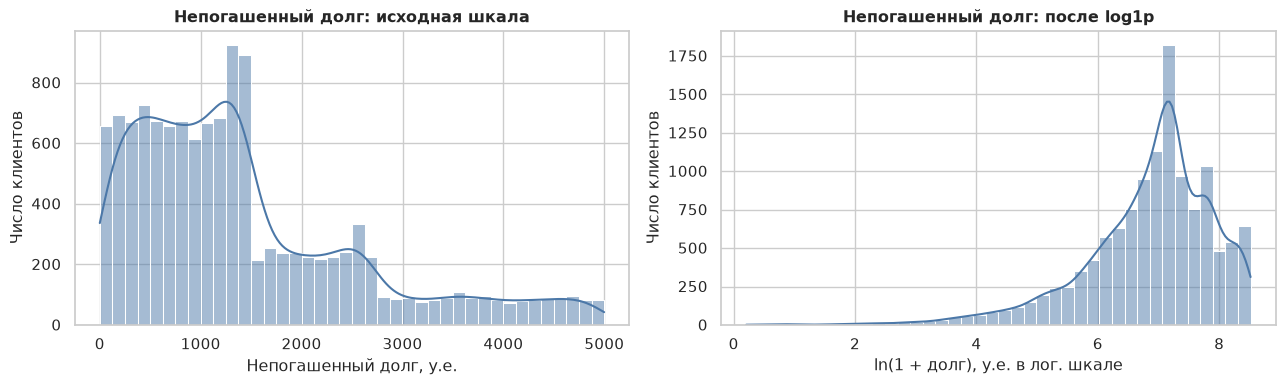

In [7]:
LOG_FEATURES = ["Annual_Income", "Outstanding_Debt", "Total_EMI_per_month",
                "Amount_invested_monthly", "Monthly_Balance", "Debt_to_Annual_Income"]
log_table = pd.DataFrame({
    "асимметрия исходная": snapshot[LOG_FEATURES].skew(),
    "асимметрия после log1p": np.log1p(snapshot[LOG_FEATURES]).skew(),
})
display(log_table.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(snapshot["Outstanding_Debt"], ax=axes[0], color=BASE_COLOR, kde=True, bins=40)
axes[0].set_title("Непогашенный долг: исходная шкала")
axes[0].set_xlabel(label("Outstanding_Debt"))
axes[0].set_ylabel("Число клиентов")
sns.histplot(np.log1p(snapshot["Outstanding_Debt"]), ax=axes[1], color=BASE_COLOR, kde=True, bins=40)
axes[1].set_title("Непогашенный долг: после log1p")
axes[1].set_xlabel("ln(1 + долг), у.е. в лог. шкале")
axes[1].set_ylabel("Число клиентов")
plt.tight_layout()
plt.show()

### Что видно

- Доход и инвестиции после `log1p` почти симметричны (1,13 → −0,08 и 2,63 → −0,17).
- Долг, EMI и остаток **перекорректированы**: асимметрия стала отрицательной (−1,0…−1,3),
  потому что много значений около нуля превращаются в длинный левый хвост.
- Доля долга в доходе почти не изменилась (2,85 → 2,47): значения доли малы, и `log1p` для них
  почти не отличается от исходного числа.

Значит, логарифм – не универсальное решение. Для деревьев преобразование не нужно,
для линейной модели лучше квантильное преобразование или преобразование Йео–Джонсона.

## 8. Поиск выбросов по правилу IQR

В ЛР1 удалены только **невозможные** значения. Теперь ищем **статистические** выбросы – значения,
далёкие от основной массы, но возможные.

- `Q1` – 25-й перцентиль, `Q3` – 75-й; между ними половина наблюдений.
- `IQR = Q3 − Q1` – межквартильный размах.
- Выброс по Тьюки – значение меньше `Q1 − 1,5·IQR` или больше `Q3 + 1,5·IQR`.

Все операции векторные: `df[NUMERIC].quantile(0.25)` сразу даёт Q1 для всех 20 признаков,
а `(df[NUMERIC] < lower) | (df[NUMERIC] > upper)` – таблицу True/False того же размера, что и данные.
`is_outlier.sum()` считает число True в каждом столбце, `mean()` – их долю.

В таблицу попадают только признаки, где выбросы есть; `.bar(...)` рисует полоски пропорционально доле.

In [8]:
q1 = df[NUMERIC].quantile(0.25)
q3 = df[NUMERIC].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_outlier = (df[NUMERIC] < lower) | (df[NUMERIC] > upper)

outliers = pd.DataFrame({
    "Q1": q1, "медиана": df[NUMERIC].median(), "Q3": q3,
    "верхняя граница": upper, "max": df[NUMERIC].max(),
    "выбросов, шт.": is_outlier.sum(),
    "выбросов, %": is_outlier.mean().mul(100),
}).sort_values("выбросов, %", ascending=False)
outliers[outliers["выбросов, шт."] > 0].style.format({
    "Q1": "{:,.2f}", "медиана": "{:,.2f}", "Q3": "{:,.2f}", "верхняя граница": "{:,.2f}",
    "max": "{:,.2f}", "выбросов, шт.": "{:,.0f}", "выбросов, %": "{:.2f}",
}).bar(subset=["выбросов, %"], color="#f2b6b6")

,Q1,медиана,Q3,верхняя граница,max,"выбросов, шт.","выбросов, %"
Debt_to_Annual_Income,0.01,0.03,0.07,0.16,0.68,"10,496",10.50
Amount_invested_monthly,73.73,129.36,234.35,475.27,"1,977.33","8,201",8.20
Monthly_Balance,270.32,337.27,471.93,774.34,"1,602.04","7,657",7.66
Outstanding_Debt,566.07,"1,166.15","1,945.96","4,015.80","4,998.07","5,272",5.27
Total_EMI_per_month,29.27,66.50,147.68,325.30,"16,305.00","5,115",5.12
Delay_from_due_date,10.00,18.00,28.00,55.00,67.00,"4,002",4.00
EMI_to_Monthly_Income,0.01,0.02,0.04,0.08,1.48,"3,513",3.51
Monthly_Inhand_Salary,"1,626.72","3,094.83","5,961.66","12,464.08","15,204.63","2,008",2.01
Annual_Income,"19,342.97","36,999.71","71,683.47","150,194.22","179,987.28","2,000",2.00
Num_Credit_Inquiries,3.00,5.00,8.00,15.50,49.00,786,0.79


### Что видно

Больше всего «выбросов» у доли долга в доходе (10,5%), инвестиций (8,2%), остатка (7,7%), долга (5,3%)
и EMI (5,1%). Это признаки с длинным правым хвостом: правило 1,5·IQR рассчитано на симметричные
распределения и для асимметричных отмечает естественный хвост.

Выброс по IQR **не означает ошибку**. Это сигнал посмотреть на значения внимательнее.

## 9. Боксплоты выбросов

Боксплот («ящик с усами»): ящик – от Q1 до Q3, линия внутри – медиана, усы – до самых дальних
значений в пределах 1,5·IQR, точки за усами – выбросы. Здесь выбросы окрашены красным.

Для EMI и доли EMI ось X логарифмическая (`set_xscale("log")`): иначе основной ящик сжался бы в линию
у нуля. В заголовок каждого графика подставлена доля выбросов из предыдущей ячейки.

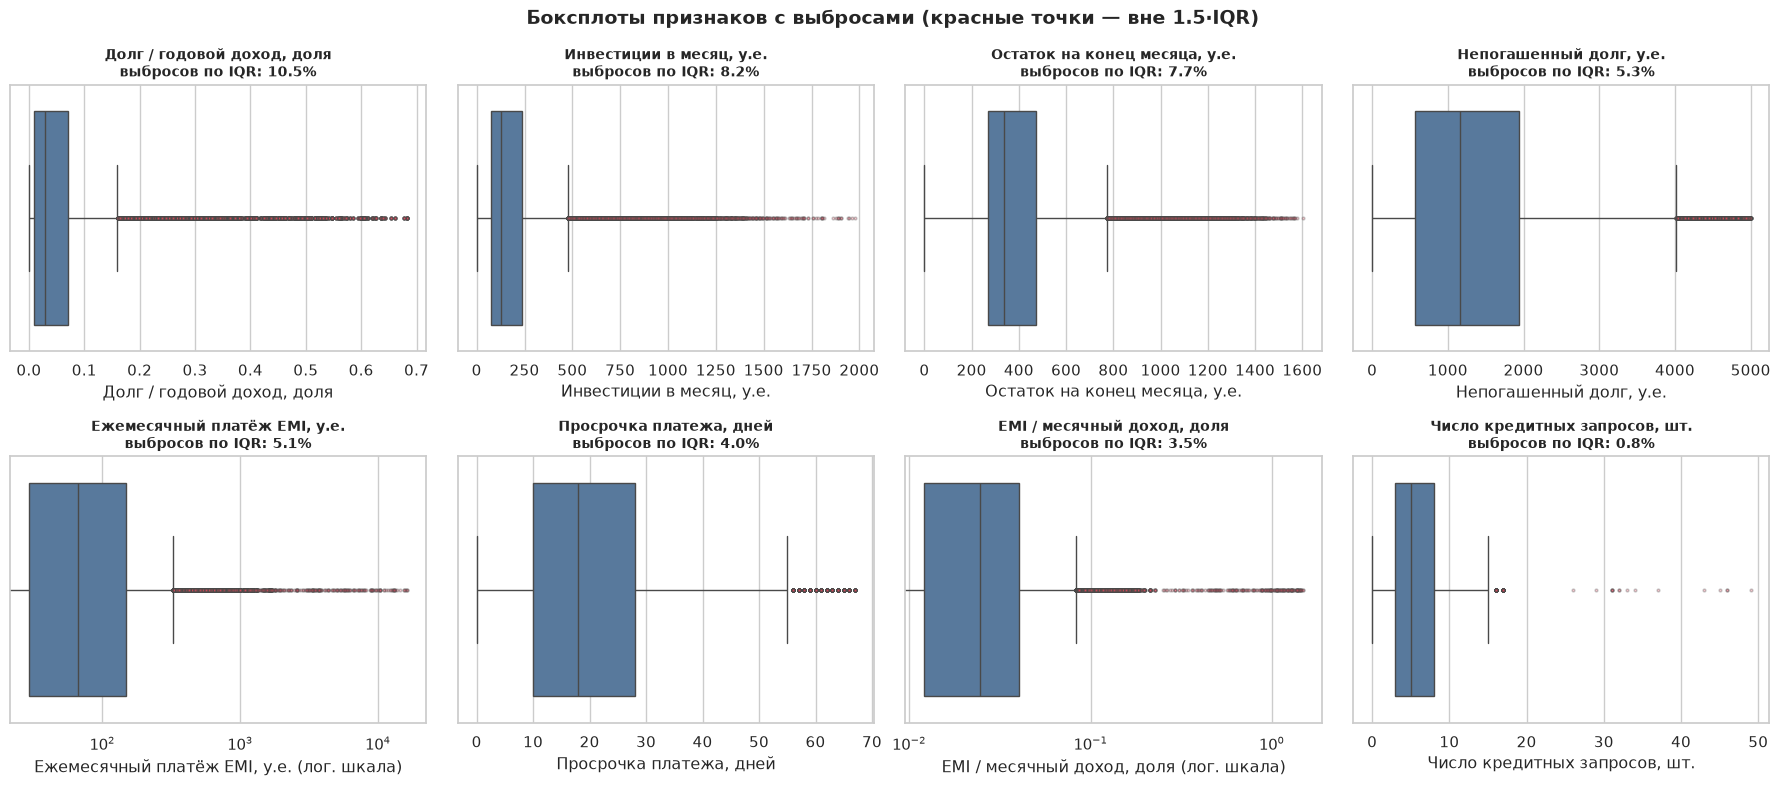

In [9]:
OUTLIER_FEATURES = ["Debt_to_Annual_Income", "Amount_invested_monthly", "Monthly_Balance",
                    "Outstanding_Debt", "Total_EMI_per_month", "Delay_from_due_date",
                    "EMI_to_Monthly_Income", "Num_Credit_Inquiries"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, column in zip(axes.flat, OUTLIER_FEATURES):
    sns.boxplot(x=df[column], ax=ax, color=BASE_COLOR, fliersize=2,
                flierprops={"marker": "o", "markerfacecolor": "#d1495b", "alpha": 0.3})
    ax.set_title(f"{label(column)}\nвыбросов по IQR: {is_outlier[column].mean():.1%}", fontsize=10)
    ax.set_xlabel(label(column))
    if column in {"Total_EMI_per_month", "EMI_to_Monthly_Income"}:
        ax.set_xscale("log")
        ax.set_xlabel(label(column) + " (лог. шкала)")
fig.suptitle("Боксплоты признаков с выбросами (красные точки — вне 1.5·IQR)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Что видно

У денежных признаков точки за усами образуют сплошной «шлейф», а не отдельные изолированные значения.
Это продолжение распределения, а не ошибки ввода. Отдельно стоящие точки видны только у EMI.

## 10. Подозрительные хвосты и связь выбросов с рейтингом

Проверяем несколько конкретных вопросов:

- в скольких строках EMI больше месячного дохода – по смыслу такое долго продолжаться не может;
- сколько строк с очень большим EMI, числом просрочек и кредитных запросов;
- главное – **доля `Poor` среди выбросов и среди остальных**. Если среди выбросов `Poor` заметно больше,
  выбросы несут информацию о риске, и удалять их нельзя.

`df.loc[is_outlier[column], "Credit_Score"] == "Poor"` – True для строк-выбросов с рейтингом `Poor`;
`.mean()` от True/False даёт долю.

In [10]:
# Детальнее про самые подозрительные хвосты.
emi_over_income = df["EMI_to_Monthly_Income"] > 1
print(f"EMI больше месячного дохода: {emi_over_income.sum()} строк "
      f"({emi_over_income.mean():.2%}), клиентов: {df.loc[emi_over_income, 'Customer_ID'].nunique()}")
print(f"EMI > 2000 у.е.: {(df['Total_EMI_per_month'] > 2000).sum()} строк; "
      f"медиана EMI = {df['Total_EMI_per_month'].median():.1f} у.е.")
print(f"Просроченных платежей > 30: {(df['Num_of_Delayed_Payment'] > 30).sum()} строк")
print(f"Кредитных запросов > 20: {(df['Num_Credit_Inquiries'] > 20).sum()} строк")

print("\nДоля Poor среди выбросов и остальных:")
for column in ["Outstanding_Debt", "Delay_from_due_date", "Debt_to_Annual_Income", "Total_EMI_per_month"]:
    poor_out = (df.loc[is_outlier[column], "Credit_Score"] == "Poor").mean()
    poor_in = (df.loc[~is_outlier[column], "Credit_Score"] == "Poor").mean()
    print(f"  {column:<24} выбросы: {poor_out:6.1%}   остальные: {poor_in:6.1%}")

EMI больше месячного дохода: 79 строк (0.08%), клиентов: 79
EMI > 2000 у.е.: 158 строк; медиана EMI = 66.5 у.е.
Просроченных платежей > 30: 12 строк
Кредитных запросов > 20: 16 строк

Доля Poor среди выбросов и остальных:
  Outstanding_Debt         выбросы:  47.5%   остальные:  28.0%
  Delay_from_due_date      выбросы:  65.5%   остальные:  27.5%
  Debt_to_Annual_Income    выбросы:  55.7%   остальные:  25.9%
  Total_EMI_per_month      выбросы:  26.2%   остальные:  29.1%


### Что видно и почему выбросы не удаляем

- EMI больше дохода – 79 строк (0,08%) у 79 разных клиентов; передаём заказчику как подозрительные.
- Среди выбросов по просрочке `Poor` – 65,5% против 27,5% у остальных; по доле долга – 55,7% против 25,9%;
  по долгу – 47,5% против 28,0%. Выбросы – это как раз самые рискованные клиенты.
- Удаление 5–10% «выбросов» убрало бы именно тех, кого модель должна распознавать.

Поэтому выбросы сохраняем, а дальше используем устойчивые к ним методы: медианы и ранги.

## 11. Корреляционная матрица Спирмена

Корреляция показывает, насколько согласованно меняются два признака: от −1 (один растёт – другой
падает) до +1 (растут вместе); 0 – согласованного изменения нет.

Почему **Спирмен**, а не Пирсон:

1. распределения ненормальны и асимметричны;
2. есть выбросы, а Пирсон к ним чувствителен;
3. цель `Credit_Score` порядковая, у неё нет «расстояний» между классами.

Спирмен заменяет значения их рангами (местами в отсортированном ряду) и считает корреляцию рангов.
Поэтому он ловит любую **монотонную** связь, не обязательно прямолинейную.

`snapshot[...].corr(method="spearman")` считает матрицу 21×21 (20 признаков + `Score_Rank`) на срезе.
`np.triu(..., k=1)` – маска верхнего треугольника: матрица симметрична, и каждую пару достаточно
увидеть один раз. Маска пригодится для поиска пар и для heatmap.

In [11]:
corr = snapshot[NUMERIC + ["Score_Rank"]].corr(method="spearman")
# Маска верхнего треугольника: каждая пара признаков учитывается один раз.
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
corr.round(2)

,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,Credit_History_Months,Debt_to_Annual_Income,EMI_to_Monthly_Income,Investment_to_Monthly_Income,Score_Rank
Age,1.000,0.080,0.080,-0.180,-0.130,-0.200,-0.200,-0.160,-0.170,-0.150,-0.230,-0.200,0.010,-0.080,0.050,0.110,0.220,-0.170,-0.170,-0.030,0.130
Annual_Income,0.080,1.000,0.990,-0.270,-0.210,-0.300,-0.250,-0.240,-0.260,-0.160,-0.270,-0.280,0.140,0.490,0.650,0.600,0.270,-0.730,-0.210,-0.320,0.190
Monthly_Inhand_Salary,0.080,0.990,1.000,-0.270,-0.200,-0.290,-0.250,-0.240,-0.260,-0.160,-0.270,-0.270,0.140,0.480,0.650,0.610,0.270,-0.720,-0.220,-0.320,0.190
Num_Bank_Accounts,-0.180,-0.270,-0.270,1.000,0.430,0.590,0.460,0.570,0.590,0.300,0.510,0.500,-0.070,0.110,-0.180,-0.310,-0.490,0.470,0.380,0.080,-0.340
Num_Credit_Card,-0.130,-0.210,-0.200,0.430,1.000,0.470,0.380,0.440,0.400,0.200,0.420,0.460,-0.050,0.110,-0.140,-0.250,-0.400,0.410,0.320,0.060,-0.340
Interest_Rate,-0.200,-0.300,-0.290,0.590,0.470,1.000,0.530,0.570,0.580,0.340,0.610,0.610,-0.070,0.140,-0.200,-0.350,-0.580,0.560,0.440,0.090,-0.420
Num_of_Loan,-0.200,-0.250,-0.250,0.460,0.380,0.530,1.000,0.450,0.460,0.310,0.550,0.560,-0.080,0.550,-0.170,-0.480,-0.600,0.500,0.840,0.070,-0.320
Delay_from_due_date,-0.160,-0.240,-0.240,0.570,0.440,0.570,0.450,1.000,0.550,0.270,0.510,0.520,-0.050,0.140,-0.160,-0.300,-0.480,0.470,0.380,0.070,-0.380
Num_of_Delayed_Payment,-0.170,-0.260,-0.260,0.590,0.400,0.580,0.460,0.550,1.000,0.290,0.490,0.480,-0.070,0.120,-0.180,-0.310,-0.490,0.460,0.380,0.080,-0.310
Changed_Credit_Limit,-0.150,-0.160,-0.160,0.300,0.200,0.340,0.310,0.270,0.290,1.000,0.350,0.320,-0.020,0.100,-0.110,-0.190,-0.390,0.300,0.270,0.040,-0.140


### Как читать знак

`Score_Rank` растёт, когда рейтинг улучшается. Значит, **отрицательная** корреляция признака
с `Score_Rank` означает «больше признак – хуже рейтинг», положительная – «больше признак – лучше рейтинг».

## 12. Связь каждого признака с рейтингом

`corr["Score_Rank"]` – столбец корреляций всех признаков с рейтингом; `drop("Score_Rank")` убирает
единицу на диагонали; `sort_values()` упорядочивает от самой отрицательной к самой положительной.

Горизонтальная столбчатая диаграмма: красные столбцы – рост признака связан с ухудшением рейтинга,
зелёные – с улучшением. Пунктир ±0,3 – условная граница умеренной связи.

Таблица под графиком отсортирована по модулю (`key=abs`): сильная отрицательная связь
так же важна, как сильная положительная.

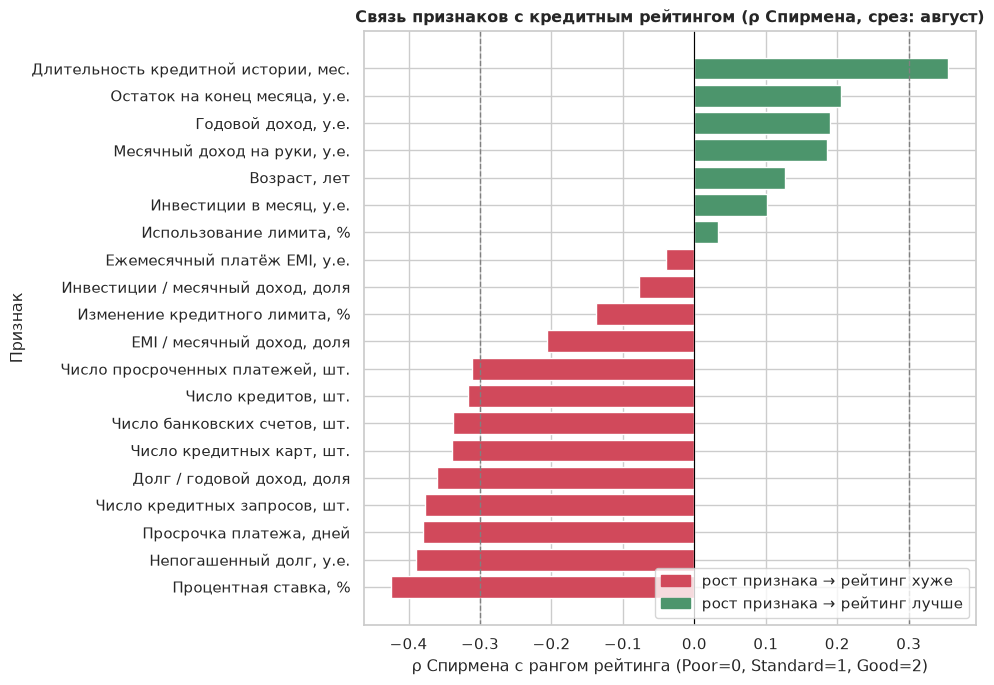

,ρ с рейтингом
Interest_Rate,-0.424
Outstanding_Debt,-0.389
Delay_from_due_date,-0.380
Num_Credit_Inquiries,-0.378
Debt_to_Annual_Income,-0.360
Credit_History_Months,0.355
Num_Credit_Card,-0.339
Num_Bank_Accounts,-0.338
Num_of_Loan,-0.317
Num_of_Delayed_Payment,-0.312


In [12]:
target_corr = corr["Score_Rank"].drop("Score_Rank").sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
colors = [SCORE_COLORS["Poor"] if v < 0 else SCORE_COLORS["Good"] for v in target_corr]
ax.barh([label(c) for c in target_corr.index], target_corr.values, color=colors)
for threshold in (-0.3, 0.3):
    ax.axvline(threshold, color="grey", linestyle="--", linewidth=1)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Связь признаков с кредитным рейтингом (ρ Спирмена, срез: август)")
ax.set_xlabel("ρ Спирмена с рангом рейтинга (Poor=0, Standard=1, Good=2)")
ax.set_ylabel("Признак")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=SCORE_COLORS["Poor"], label="рост признака → рейтинг хуже"),
                   Patch(color=SCORE_COLORS["Good"], label="рост признака → рейтинг лучше")],
          loc="lower right")
plt.tight_layout()
plt.show()

display(target_corr.to_frame("ρ с рейтингом").sort_values("ρ с рейтингом", key=abs, ascending=False).round(3))

### Что видно

- Сильнее всего с рейтингом связаны ставка (−0,42), долг (−0,39), просрочка (−0,38), число запросов (−0,38),
  доля долга в доходе (−0,36) и длительность истории (+0,35). Это умеренные связи.
- Доход, остаток и возраст связаны слабо (|ρ| < 0,21).
- Абсолютный EMI почти не связан с рейтингом (−0,04), а доля EMI в доходе – заметнее (−0,21):
  признак, созданный в ЛР1, оказался полезнее исходного.
- Использование кредитного лимита практически не связано с рейтингом (0,03).

## 13. Сильно связанные между собой признаки

Если два признака почти дублируют друг друга, это **мультиколлинеарность**. Для деревьев это не страшно,
а линейная модель делит вес между дублями непредсказуемо, и коэффициенты становится трудно объяснять.

`corr.drop(...)` убирает рейтинг, `.where(mask[:-1, :-1])` оставляет только верхний треугольник
(остальное превращается в `NaN`), `.stack()` разворачивает матрицу в список пар без `NaN`.
Оставляем пары с |ρ| ≥ 0,6.

In [13]:
# Сильно связанные между собой признаки (мультиколлинеарность) — важно для линейных моделей.
pairs = corr.drop(index="Score_Rank", columns="Score_Rank").where(mask[:-1, :-1]).stack()
strong_pairs = pairs[pairs.abs() >= 0.6].sort_values(key=abs, ascending=False)
strong_pairs.rename("ρ Спирмена").to_frame().round(3)

,,ρ Спирмена
Annual_Income,Monthly_Inhand_Salary,0.994
Num_of_Loan,EMI_to_Monthly_Income,0.841
Outstanding_Debt,Debt_to_Annual_Income,0.837
Annual_Income,Debt_to_Annual_Income,-0.727
Monthly_Inhand_Salary,Debt_to_Annual_Income,-0.723
Monthly_Balance,Investment_to_Monthly_Income,-0.688
Total_EMI_per_month,EMI_to_Monthly_Income,0.675
Monthly_Inhand_Salary,Amount_invested_monthly,0.651
Annual_Income,Amount_invested_monthly,0.648
Num_Credit_Inquiries,Credit_History_Months,-0.617


### Что видно

- Годовой и месячный доход – 0,99: фактически один признак в двух единицах. В линейной модели оставить один.
- Число кредитов и доля EMI в доходе – 0,84; долг и доля долга в доходе – 0,84. Вторые признаки
  вычислены из первых в ЛР1, поэтому связь ожидаема.
- Ставка, число запросов и долг связаны между собой (≈ 0,6): «рискованный профиль» описывается
  группой согласованных признаков. В модели их вклад будет частично перераспределяться.

## 14. Heatmap корреляций

Тепловая карта показывает матрицу цветом. `sns.heatmap`:

- `mask=mask` скрывает верхний треугольник – дубли пар;
- `cmap="RdBu_r"`, `vmin=-1`, `vmax=1`, `center=0` – красный для положительных связей, синий для
  отрицательных, белый около нуля; шкала одна и та же для всех клеток;
- `annot=True, fmt=".2f"` – подписи значений с двумя знаками.

`short` заменяет подчёркивания в названиях пробелами, а `Score_Rank` подписан как «▶ Credit Score (ранг)»,
чтобы строку рейтинга было легко найти.

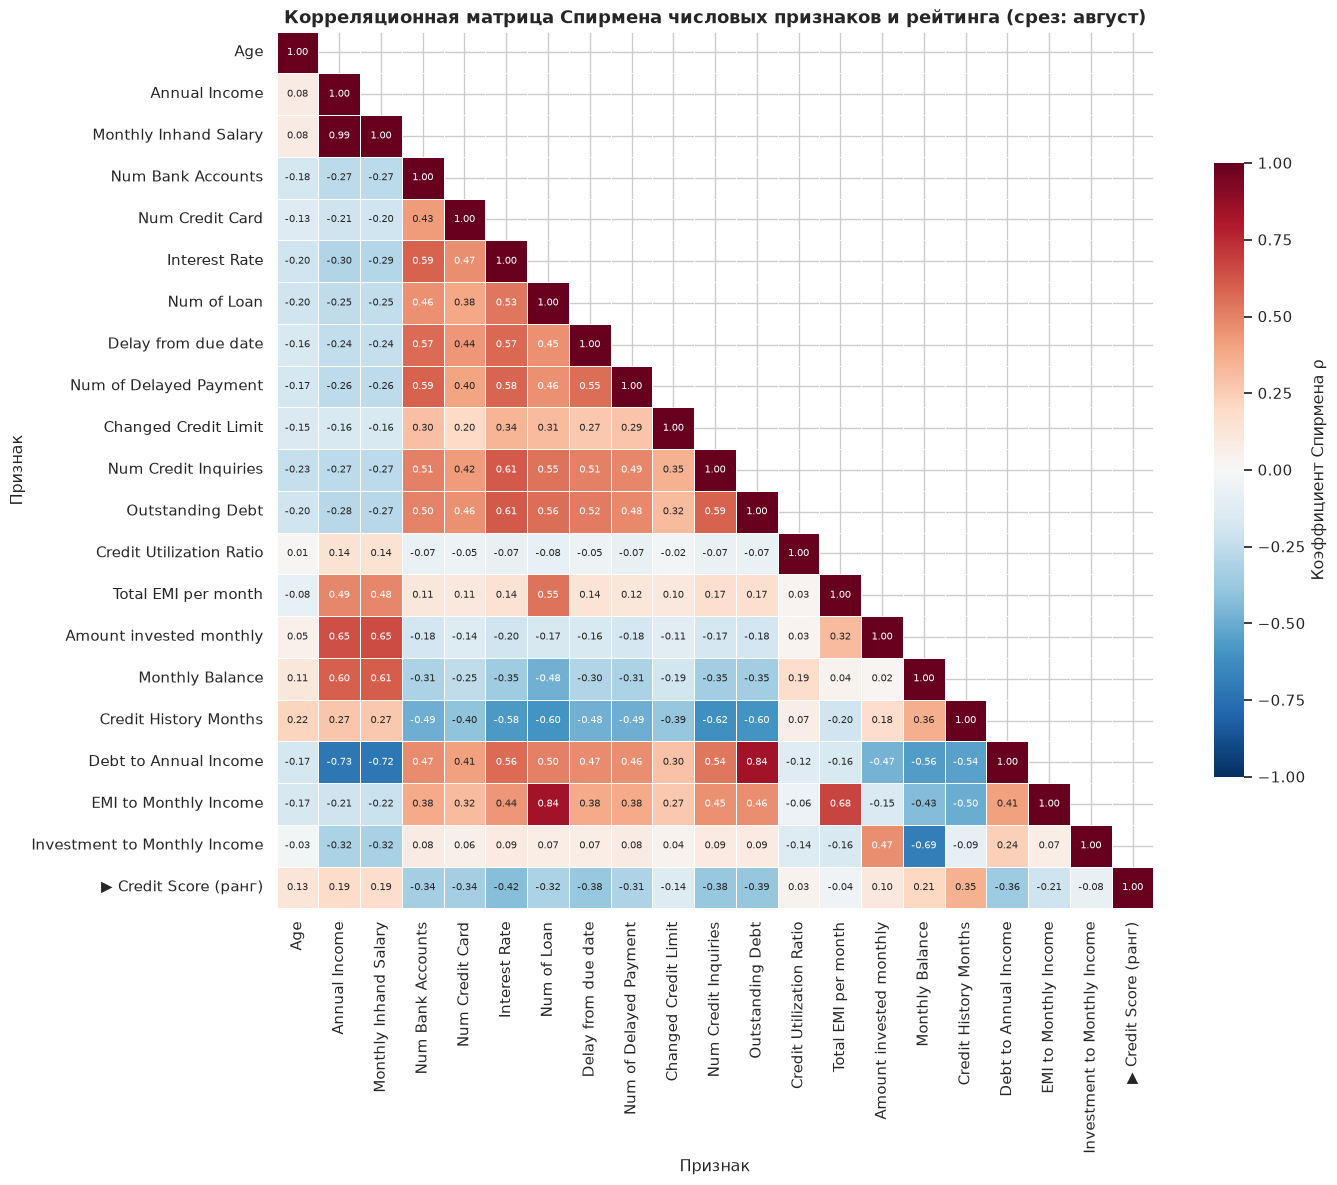

In [14]:
short = {c: c.replace("_", " ") for c in corr.columns}
short["Score_Rank"] = "▶ Credit Score (ранг)"

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr.rename(index=short, columns=short), mask=mask, cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.4, square=True,
            cbar_kws={"label": "Коэффициент Спирмена ρ", "shrink": 0.7}, ax=ax)
ax.set_title("Корреляционная матрица Спирмена числовых признаков и рейтинга (срез: август)", fontsize=13)
ax.set_xlabel("Признак")
ax.set_ylabel("Признак")
plt.tight_layout()
plt.show()

### Что видно

Нижняя строка – связи с рейтингом: синие клетки у ставки, долга, просрочки, запросов, красная – у истории.
Красный блок в середине – взаимосвязанные признаки «рискованного профиля». Самая тёмная клетка вне
диагонали – годовой и месячный доход (0,99).

## 15. Статистическая проверка гипотез

Корреляция даёт одно число. Теперь проверяем гипотезы строже: различаются ли распределения признака
между тремя классами рейтинга.

**Числовой признак × 3 класса → критерий Краскела–Уоллиса** (`stats.kruskal`). Это непараметрический
аналог однофакторного дисперсионного анализа (ANOVA): он сравнивает ранги, а не средние, и не требует
нормальности. H₀: распределение признака одинаково во всех классах.

**Категориальный признак × рейтинг → χ² Пирсона** (`stats.chi2_contingency`) по таблице сопряжённости
`pd.crosstab`. H₀: признак и рейтинг независимы.

При n = 12 500 почти любое различие «значимо», поэтому главное – **размер эффекта**:

- для Краскела–Уоллиса ε² = (H − k + 1) / (n − k): 0,01 – малый, 0,06 – средний, 0,14 – большой;
- для χ² – V Крамера = √(χ² / (n · (min(строк, столбцов) − 1))): 0,1 – слабая, 0,3 – умеренная, 0,5 – сильная.

Проверяется 13 признаков сразу. Чем больше проверок, тем выше шанс случайно получить p < 0,05.
**Поправка Бонферрони** делит порог на число проверок: 0,05 / 13 ≈ 0,0038.

Функции `kruskal_test` и `chi2_test` возвращают словарь результатов; список `TESTS` задаёт, какой
признак к какой гипотезе относится и каким тестом проверяется. В `kruskal_test` дополнительно
считаются медианы признака в каждом классе – по ним видно **направление** различия.

In [15]:
def kruskal_test(frame, column):
    groups = [frame.loc[frame["Credit_Score"] == score, column] for score in SCORE_ORDER]
    h_stat, p_value = stats.kruskal(*groups)
    n, k = len(frame), len(groups)
    medians = frame.groupby("Credit_Score", observed=True)[column].median().reindex(SCORE_ORDER)
    return {"тест": "Краскел–Уоллис", "статистика": h_stat, "p-value": p_value,
            "эффект": (h_stat - k + 1) / (n - k), "мера эффекта": "ε²",
            "Good": medians["Good"], "Standard": medians["Standard"], "Poor": medians["Poor"]}

def chi2_test(frame, column):
    table = pd.crosstab(frame[column], frame["Credit_Score"])
    chi2, p_value, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return {"тест": "χ²", "статистика": chi2, "p-value": p_value,
            "эффект": cramers_v, "мера эффекта": "V Крамера"}

def effect_strength(row):
    e = row["эффект"]
    if row["мера эффекта"] == "ε²":
        return "большой" if e >= 0.14 else "средний" if e >= 0.06 else "малый" if e >= 0.01 else "нет"
    return "сильная" if e >= 0.5 else "умеренная" if e >= 0.3 else "слабая" if e >= 0.1 else "нет"

TESTS = [
    ("H1", "Outstanding_Debt", kruskal_test),
    ("H1", "Delay_from_due_date", kruskal_test),
    ("H1", "Num_of_Delayed_Payment", kruskal_test),
    ("H2", "Interest_Rate", kruskal_test),
    ("H3", "Credit_Mix", chi2_test),
    ("H4", "Num_Credit_Inquiries", kruskal_test),
    ("H5", "EMI_to_Monthly_Income", kruskal_test),
    ("доп.", "Credit_History_Months", kruskal_test),
    ("доп.", "Annual_Income", kruskal_test),
    ("доп.", "Age", kruskal_test),
    ("доп.", "Payment_of_Min_Amount", chi2_test),
    ("доп.", "Payment_Behaviour", chi2_test),
    ("доп.", "Occupation", chi2_test),
]
results = pd.DataFrame([{"гипотеза": h, "признак": col, **fn(snapshot, col)} for h, col, fn in TESTS])
bonferroni_alpha = 0.05 / len(results)
results["значимо (Бонферрони)"] = np.where(results["p-value"] < bonferroni_alpha, "да", "нет")
results["сила эффекта"] = results.apply(effect_strength, axis=1)
print(f"Порог с поправкой Бонферрони: α = 0.05 / {len(results)} = {bonferroni_alpha:.4f}")
results.set_index(["гипотеза", "признак"]).style.format({
    "статистика": "{:,.1f}", "p-value": "{:.1e}", "эффект": "{:.3f}",
    "Good": "{:,.3f}", "Standard": "{:,.3f}", "Poor": "{:,.3f}",
}, na_rep="—")

Порог с поправкой Бонферрони: α = 0.05 / 13 = 0.0038


### Что видно

- Все признаки, кроме профессии, значимы и с поправкой Бонферрони.
- Большой эффект (ε² ≥ 0,14): ставка (0,181), долг (0,153), просрочка (0,146), запросы (0,143).
- Медианы меняются монотонно: долг 747 → 1 041 → 1 826 у.е., просрочка 11 → 18 → 26 дней,
  ставка 8 → 13 → 20%, запросы 4 → 6 → 9 для `Good` → `Standard` → `Poor`.
- Доля EMI: эффект малый (ε² = 0,044), хотя направление совпадает с гипотезой.
- Профессия: p ≈ 0,74, H₀ не отвергается – связи с рейтингом не обнаружено.

## 16. H3 подробнее: `Credit_Mix` и отношение шансов

`pd.crosstab(..., normalize="index")` даёт долю каждого рейтинга **внутри** каждой категории
`Credit_Mix`: строки в сумме дают 100%.

**Отношение шансов** (odds ratio, OR) отвечает на вопрос: во сколько раз шансы оказаться `Poor`
при `Credit_Mix = Bad` выше, чем при остальных категориях. Шансы – это p / (1 − p), а не вероятность.
`stats.fisher_exact` считает OR и точный p-value по таблице 2×2 (Bad / не Bad × Poor / не Poor).

In [16]:
# H3 подробнее: доля каждого рейтинга внутри категории Credit_Mix.
mix_table = (pd.crosstab(snapshot["Credit_Mix"], snapshot["Credit_Score"], normalize="index")
             .reindex(index=["Good", "Standard", "Bad"], columns=SCORE_ORDER).mul(100))
display(mix_table.round(1).rename_axis(index="Credit_Mix", columns="Credit_Score, %"))

# Отношение шансов «Poor vs не Poor» для Bad против остальных категорий.
bad = snapshot["Credit_Mix"] == "Bad"
poor = snapshot["Credit_Score"] == "Poor"
odds_ratio, p_fisher = stats.fisher_exact(pd.crosstab(bad, poor).values)
print(f"Отношение шансов оказаться Poor при Credit_Mix=Bad: OR = {odds_ratio:.2f}, p = {p_fisher:.1e}")

"Credit_Score, %",Good,Standard,Poor
Credit_Mix,,,
Good,44.600,39.400,16.000
Standard,11.100,65.400,23.400
Bad,2.800,41.700,55.600


Отношение шансов оказаться Poor при Credit_Mix=Bad: OR = 4.86, p = 5.5e-278


### Что видно

При `Bad` доля `Poor` 55,6%, а `Good` – только 2,8%. При `Good` – наоборот: 16,0% и 44,6%.
OR = 4,86: шансы оказаться `Poor` при `Bad` почти в 5 раз выше. H3 подтверждается.

## 17. Ранжирование факторов

Нужно сравнить на одной шкале числовые признаки (ε²) и категориальные (V Крамера).
ε² – доля объяснённой «рангами» изменчивости, она похожа на квадрат корреляции;
V Крамера – на саму корреляцию. Поэтому из ε² берётся корень: √ε² сопоставим с V.
Это приближённое сравнение, но для выбора кандидатов его достаточно.

`np.where(условие, a, b)` выбирает √ε² для числовых признаков и V для категориальных.
Первые пять столбцов на графике окрашены красным – кандидаты в топ-5.

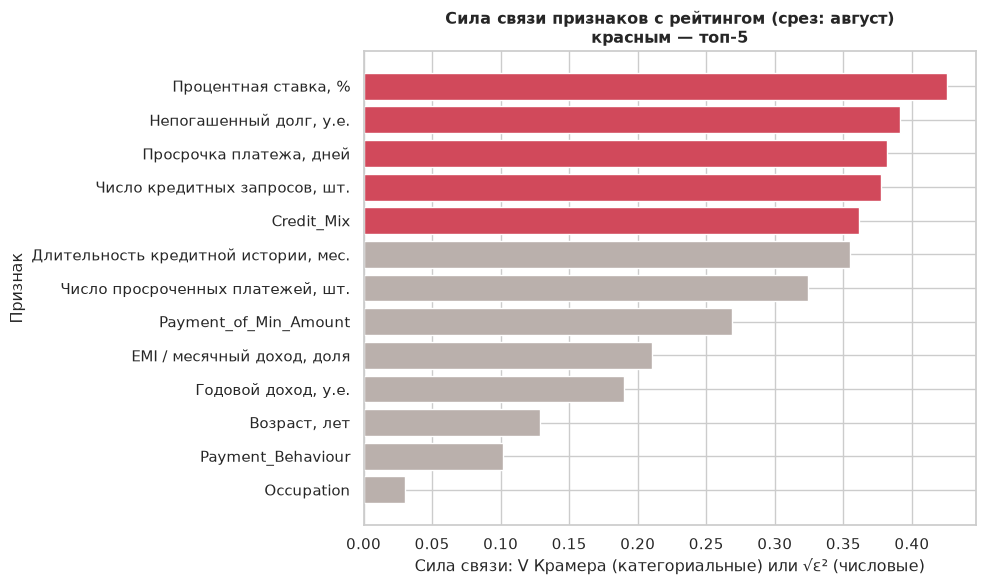

,признак,мера эффекта,эффект,сопоставимая сила (√ε² или V)
1,Interest_Rate,ε²,0.181,0.425
2,Outstanding_Debt,ε²,0.153,0.392
3,Delay_from_due_date,ε²,0.146,0.382
4,Num_Credit_Inquiries,ε²,0.143,0.378
5,Credit_Mix,V Крамера,0.361,0.361
6,Credit_History_Months,ε²,0.126,0.355
7,Num_of_Delayed_Payment,ε²,0.105,0.324
8,Payment_of_Min_Amount,V Крамера,0.269,0.269
9,EMI_to_Monthly_Income,ε²,0.044,0.210
10,Annual_Income,ε²,0.036,0.190


In [17]:
# Ранжирование факторов по размеру эффекта — кандидаты в топ-5 для ЛР3.
# Чтобы сравнивать ε² и V на одной шкале, переводим ε² в эквивалент корреляции √ε².
ranking = results[["признак", "мера эффекта", "эффект"]].copy()
ranking["сопоставимая сила (√ε² или V)"] = np.where(
    ranking["мера эффекта"] == "ε²", np.sqrt(ranking["эффект"]), ranking["эффект"])
ranking = ranking.sort_values("сопоставимая сила (√ε² или V)", ascending=False).reset_index(drop=True)
ranking.index += 1

fig, ax = plt.subplots(figsize=(10, 6))
bar_colors = [SCORE_COLORS["Poor"] if i < 5 else "#bab0ac" for i in range(len(ranking))]
ax.barh([label(c) for c in ranking["признак"]][::-1],
        ranking["сопоставимая сила (√ε² или V)"][::-1], color=bar_colors[::-1])
ax.set_title("Сила связи признаков с рейтингом (срез: август)\nкрасным — топ-5")
ax.set_xlabel("Сила связи: V Крамера (категориальные) или √ε² (числовые)")
ax.set_ylabel("Признак")
plt.tight_layout()
plt.show()
ranking.round(3)

### Что видно

Топ-5: ставка (0,43), долг (0,39), просрочка (0,38), запросы (0,38), `Credit_Mix` (0,36).
Вплотную – длительность истории (0,36) и число просроченных платежей (0,32).
В ЛР3 этот список сверяется с важностью признаков модели.

## 18. Структура рейтинга по месяцам

В наборе 8 месяцев одного года. Проверяем, меняется ли доля классов во времени.

`pd.crosstab(df["Month_Number"], df["Credit_Score"], normalize="index")` – доли классов в каждом месяце.
Здесь используем все 100 000 строк: в каждом месяце каждый клиент ровно один раз, так что внутри месяца
наблюдения не повторяются.

Слева – столбцы с накоплением: каждый столбец = 100%. Справа – те же доли линиями, так проще увидеть
изменение каждого класса. Серая полоса отмечает переход март → апрель.

χ²-тест проверяет независимость месяца и рейтинга. Оговорка: один клиент есть во всех месяцах,
поэтому наблюдения между месяцами зависимы и p-value здесь ориентировочное.

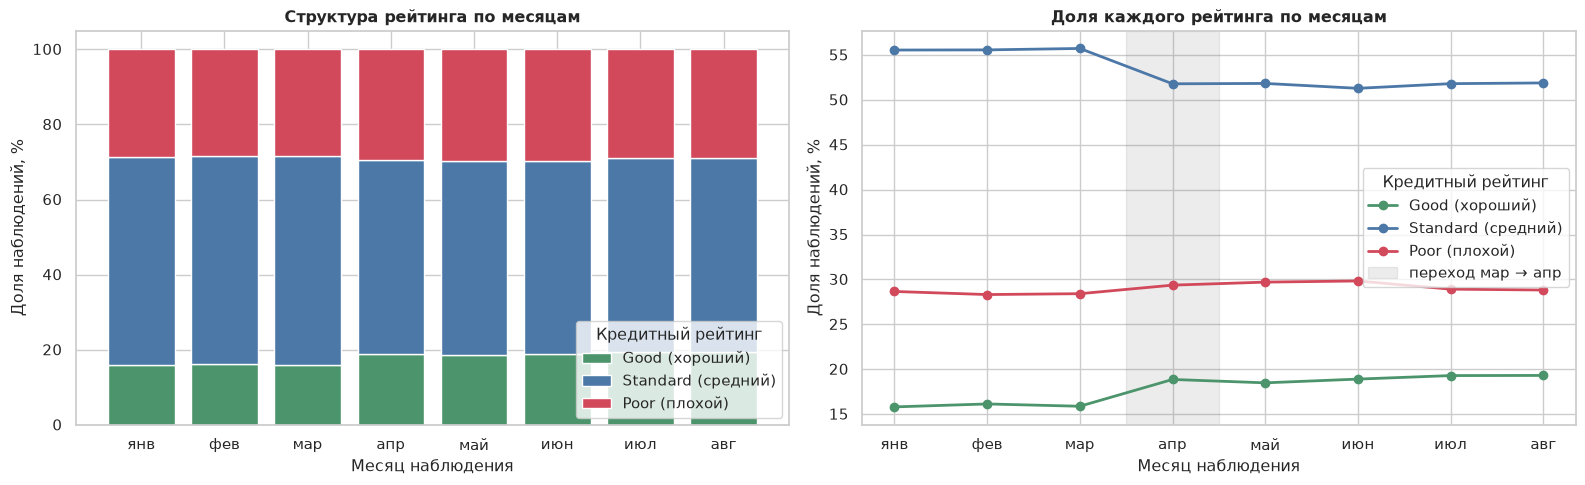

χ² независимости месяца и рейтинга: χ² = 201.8, df = 14, p = 2.3e-35
Средняя доля Good: янв–мар 15.9%, апр–авг 19.0%


In [18]:
MONTH_RU = {1: "янв", 2: "фев", 3: "мар", 4: "апр", 5: "май", 6: "июн", 7: "июл", 8: "авг"}

month_share = (pd.crosstab(df["Month_Number"], df["Credit_Score"], normalize="index")
               .reindex(columns=SCORE_ORDER).mul(100))
chi2, p_month, dof, _ = stats.chi2_contingency(pd.crosstab(df["Month_Number"], df["Credit_Score"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
bottom = np.zeros(len(month_share))
for score in SCORE_ORDER:
    axes[0].bar(month_share.index.map(MONTH_RU), month_share[score], bottom=bottom,
                color=SCORE_COLORS[score], label=SCORE_RU[score], edgecolor="white")
    bottom += month_share[score].values
axes[0].set_title("Структура рейтинга по месяцам")
axes[0].set_xlabel("Месяц наблюдения")
axes[0].set_ylabel("Доля наблюдений, %")
axes[0].legend(title="Кредитный рейтинг", loc="lower right")

for score in SCORE_ORDER:
    axes[1].plot(month_share.index.map(MONTH_RU), month_share[score], marker="o",
                 color=SCORE_COLORS[score], label=SCORE_RU[score], linewidth=2)
axes[1].axvspan(2.5, 3.5, color="grey", alpha=0.15, label="переход мар → апр")
axes[1].set_title("Доля каждого рейтинга по месяцам")
axes[1].set_xlabel("Месяц наблюдения")
axes[1].set_ylabel("Доля наблюдений, %")
axes[1].legend(title="Кредитный рейтинг", loc="center right")
plt.tight_layout()
plt.show()

print(f"χ² независимости месяца и рейтинга: χ² = {chi2:.1f}, df = {dof}, p = {p_month:.1e}")
print(f"Средняя доля Good: янв–мар {month_share.loc[1:3, 'Good'].mean():.1f}%, "
      f"апр–авг {month_share.loc[4:8, 'Good'].mean():.1f}%")

### Что видно

Доли почти постоянны внутри двух периодов: январь–март (`Good` ≈ 15,9%) и апрель–август (≈ 19,0%).
Между мартом и апрелем – ступенька примерно на 3 п.п. Плавного тренда или колебаний нет.
Такая ступенька похожа на изменение методики присвоения рейтинга с апреля – это вопрос к владельцу данных.

## 19. Динамика медиан признаков

`df.groupby("Month_Number")[TIME_FEATURES].median()` – медиана каждого признака по месяцам.
Признаки в разных единицах (дни, у.е., месяцы), поэтому на одном графике их не сравнить напрямую.
Делим каждую медиану на январскую и умножаем на 100 – получаем **индекс**: январь = 100,
значение 110 означает рост на 10% относительно января.

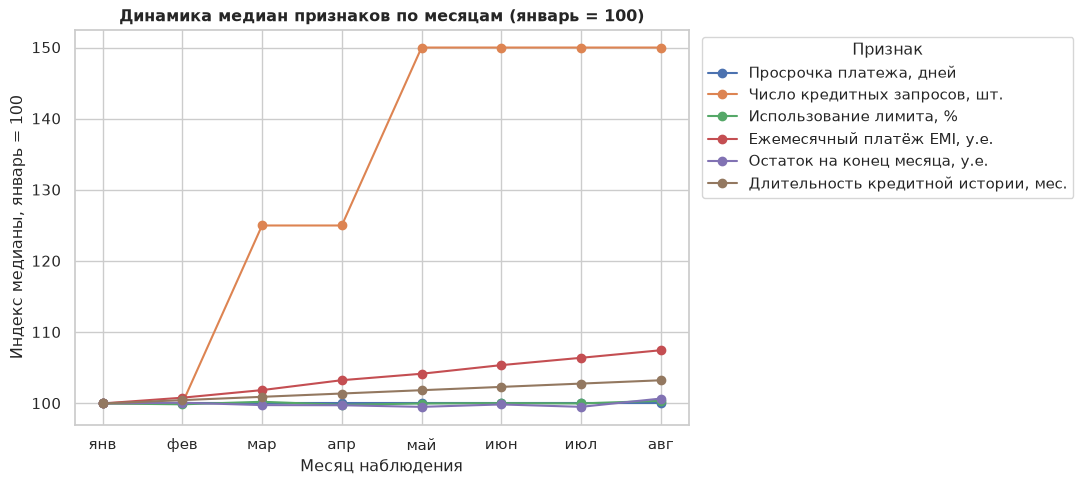

,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month,Monthly_Balance,Credit_History_Months
Month_Number,,,,,,
1,18.000,4.000,32.300,64.130,337.630,215.000
2,18.000,4.000,32.260,64.650,337.980,216.000
3,18.000,5.000,32.370,65.330,336.850,217.000
4,18.000,5.000,32.240,66.220,336.780,218.000
5,18.000,6.000,32.300,66.800,336.020,219.000
6,18.000,6.000,32.310,67.580,337.160,220.000
7,18.000,6.000,32.300,68.240,336.030,221.000
8,18.000,6.000,32.420,68.920,339.950,222.000


In [19]:
TIME_FEATURES = ["Delay_from_due_date", "Num_Credit_Inquiries", "Credit_Utilization_Ratio",
                 "Total_EMI_per_month", "Monthly_Balance", "Credit_History_Months"]
monthly_medians = df.groupby("Month_Number")[TIME_FEATURES].median()
monthly_index = monthly_medians / monthly_medians.loc[1] * 100

fig, ax = plt.subplots(figsize=(11, 5))
for column in TIME_FEATURES:
    ax.plot(monthly_index.index.map(MONTH_RU), monthly_index[column], marker="o", label=label(column))
ax.set_title("Динамика медиан признаков по месяцам (январь = 100)")
ax.set_xlabel("Месяц наблюдения")
ax.set_ylabel("Индекс медианы, январь = 100")
ax.legend(title="Признак", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()
monthly_medians.round(2)

### Что видно

- Число кредитных запросов растёт ступенями: медиана 4 → 5 → 6 (+50% к августу).
- EMI плавно растёт: 64,1 → 68,9 у.е. (≈ +7,5% за 8 месяцев).
- Длительность истории растёт ровно на 1 месяц в месяц – так она построена в ЛР1.
- Просрочка, использование лимита и остаток постоянны.

## 20. Стабильность рейтинга клиента

**Матрица переходов**: из какого рейтинга в какой клиент переходит за один месяц.

`sort_values(["Customer_ID", "Month_Number"])` упорядочивает месяцы каждого клиента.
`groupby("Customer_ID")["Credit_Score"].shift(-1)` берёт рейтинг **следующего** месяца того же клиента;
у последнего месяца следующего нет, получается `NaN`, и такие строки отбрасываются (`dropna`).
Итого 12 500 × 7 = 87 500 переходов.

`crosstab(..., normalize="index")` – в каждой строке доли переходов из данного рейтинга, сумма 100%.

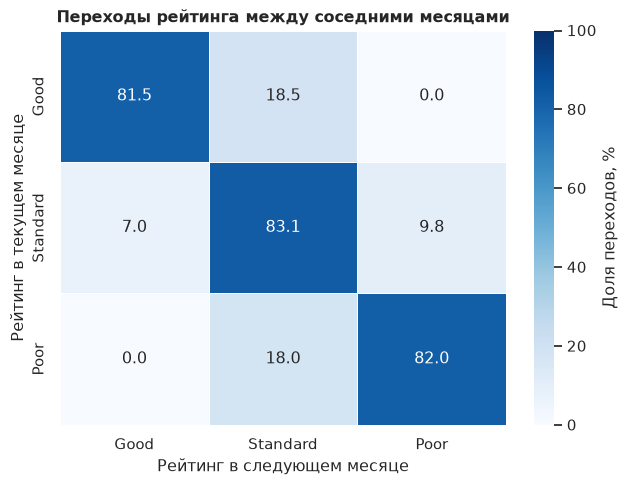

Рейтинг меняется в 17.5% переходов месяц → месяц
Хотя бы раз за 8 месяцев рейтинг менялся у 58.3% клиентов


In [20]:
# Стабильность рейтинга клиента: матрица переходов «рейтинг в месяц t → рейтинг в месяц t+1».
ordered = df.sort_values(["Customer_ID", "Month_Number"])
ordered["Next_Score"] = ordered.groupby("Customer_ID")["Credit_Score"].shift(-1)
transitions = ordered.dropna(subset=["Next_Score"])
transition_matrix = (pd.crosstab(transitions["Credit_Score"], transitions["Next_Score"], normalize="index")
                     .reindex(index=SCORE_ORDER, columns=SCORE_ORDER).mul(100))

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(transition_matrix, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "Доля переходов, %"}, ax=ax, linewidths=0.5)
ax.set_title("Переходы рейтинга между соседними месяцами")
ax.set_xlabel("Рейтинг в следующем месяце")
ax.set_ylabel("Рейтинг в текущем месяце")
plt.tight_layout()
plt.show()

changed = (transitions["Credit_Score"].astype(str) != transitions["Next_Score"].astype(str)).mean()
clients_changed = (df.groupby("Customer_ID")["Credit_Score"].nunique() > 1).mean()
print(f"Рейтинг меняется в {changed:.1%} переходов месяц → месяц")
print(f"Хотя бы раз за 8 месяцев рейтинг менялся у {clients_changed:.1%} клиентов")

### Что видно

- По диагонали ≈ 82%: в большинстве случаев рейтинг не меняется.
- Переходы только между соседними классами. Прямых переходов `Good` ↔ `Poor` за один месяц нет вовсе (0 случаев).
- При этом у 58,3% клиентов рейтинг хотя бы раз менялся за 8 месяцев.

Следствие для ЛР3: строки одного клиента очень похожи. При случайном разбиении на train/test один
клиент попадёт в обе части, и качество модели будет завышено. Разбивать нужно по `Customer_ID`.

## 21. Сезонные паттерны

`SEASON` сопоставляет номер месяца календарному сезону. В данных только январь–август, поэтому
зима неполная (январь–февраль), осени нет. `pd.Categorical(..., ordered=True)` фиксирует порядок
сезонов на графике.

Доли классов по сезонам считаются так же, как по месяцам, и показываются горизонтальными столбцами
с накоплением. Последняя строка сравнивает март (весна) с апрелем–маем, чтобы отделить эффект сезона
от ступеньки в апреле.

Credit_Score,Good,Standard,Poor,Наблюдений
Season,,,,
зима,16.000,55.600,28.500,25000
весна,17.700,53.100,29.200,37500
лето,19.200,51.700,29.200,37500


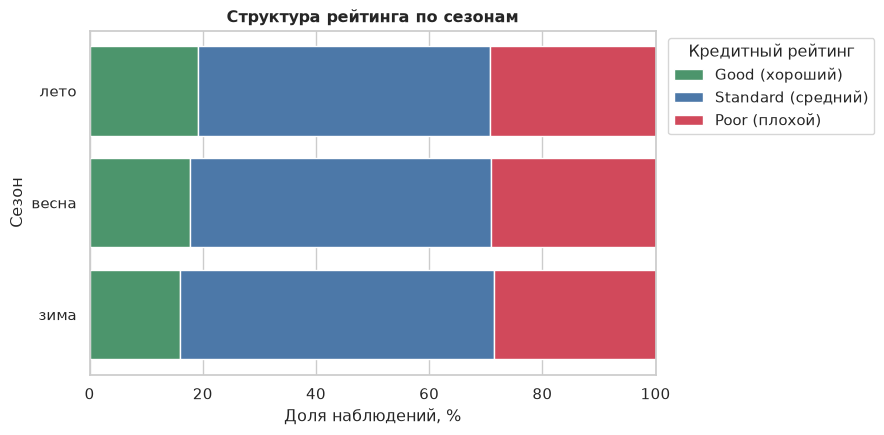

Доля Good в марте: 15.9%; в апреле–мае: 18.7%


In [21]:
SEASON = {1: "зима", 2: "зима", 3: "весна", 4: "весна", 5: "весна", 6: "лето", 7: "лето", 8: "лето"}
SEASON_ORDER = ["зима", "весна", "лето"]
df["Season"] = pd.Categorical(df["Month_Number"].map(SEASON), categories=SEASON_ORDER, ordered=True)

season_share = (pd.crosstab(df["Season"], df["Credit_Score"], normalize="index")
                .reindex(columns=SCORE_ORDER).mul(100))
season_stats = season_share.assign(**{"Наблюдений": df["Season"].value_counts().reindex(SEASON_ORDER)})
display(season_stats.round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
left = np.zeros(len(season_share))
for score in SCORE_ORDER:
    ax.barh(season_share.index.astype(str), season_share[score], left=left,
            color=SCORE_COLORS[score], label=SCORE_RU[score], edgecolor="white")
    left += season_share[score].values
ax.set_title("Структура рейтинга по сезонам")
ax.set_xlabel("Доля наблюдений, %")
ax.set_ylabel("Сезон")
ax.set_xlim(0, 100)
ax.legend(title="Кредитный рейтинг", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

march = df["Month_Number"].eq(3)
print(f"Доля Good в марте: {(df.loc[march, 'Credit_Score'] == 'Good').mean():.1%}; "
      f"в апреле–мае: {(df.loc[df['Month_Number'].isin([4, 5]), 'Credit_Score'] == 'Good').mean():.1%}")

### Что видно

Доля `Good` растёт от зимы к лету: 16,0% → 17,7% → 19,2%. Но март (весна) совпадает с зимой – 15,9%,
а рост начинается с апреля. Значит, это та же апрельская ступенька, а не сезонность.
Повторяющийся годовой цикл на 8 месяцах одного года проверить нельзя.

## 22. Гистограммы по классам рейтинга

`sns.histplot(..., hue="Credit_Score")` рисует распределение признака отдельно для каждого класса.

- `stat="density", common_norm=False` – каждый класс нормируется отдельно, площадь под каждой
  кривой равна 1. Иначе `Standard` (52% клиентов) выглядел бы «больше» просто из-за численности.
- `element="step"` – контур вместо заливки, чтобы классы не закрывали друг друга.

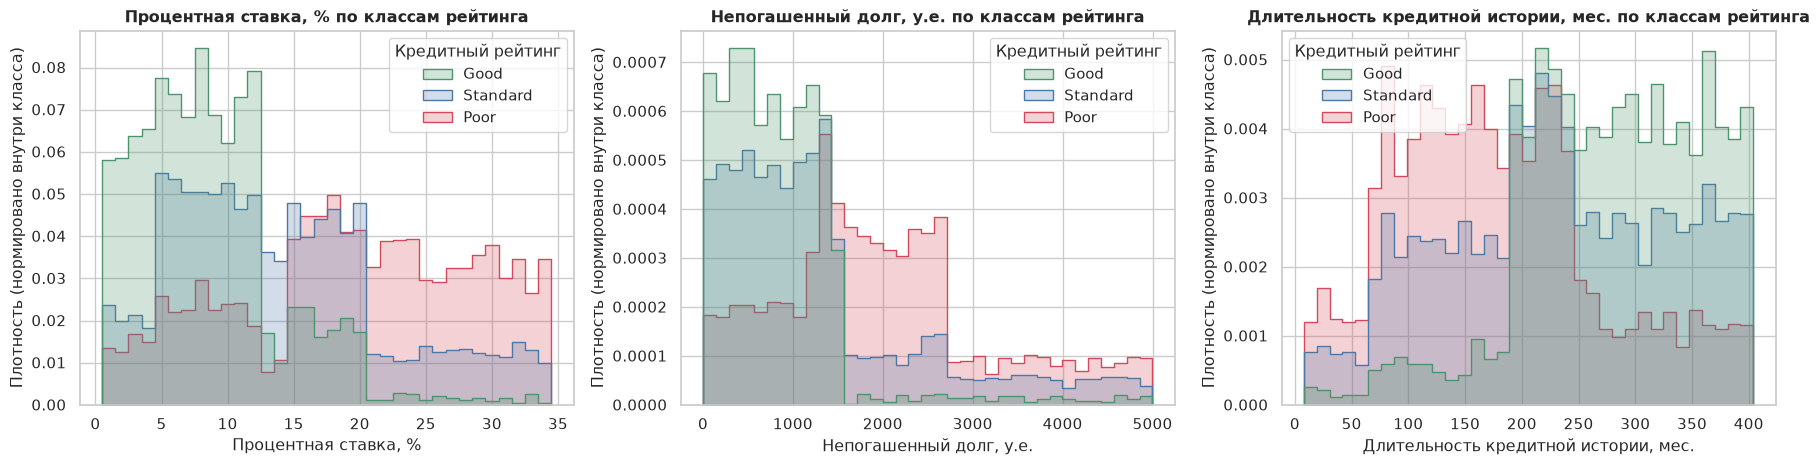

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, column in zip(axes, ["Interest_Rate", "Outstanding_Debt", "Credit_History_Months"]):
    sns.histplot(data=snapshot, x=column, hue="Credit_Score", hue_order=SCORE_ORDER,
                 palette=SCORE_COLORS, element="step", stat="density", common_norm=False,
                 discrete=(column == "Interest_Rate"), bins="auto" if column == "Interest_Rate" else 35,
                 ax=ax, alpha=0.25)
    ax.set_title(f"{label(column)} по классам рейтинга")
    ax.set_xlabel(label(column))
    ax.set_ylabel("Плотность (нормировано внутри класса)")
    ax.get_legend().set_title("Кредитный рейтинг")
plt.tight_layout()
plt.show()

### Что видно

У `Poor` ставка и долг сдвинуты вправо, история – влево. `Good` по ставке почти весь в диапазоне 1–12%,
`Poor` – в основном выше 15%. По долгу выше ~1 500 у.е. `Good` почти не встречается.
`Standard` перекрывается с обоими классами.

## 23. Боксплоты по классам

Для каждого из шести признаков – три ящика, по одному на класс. На каждом ящике подписана медиана
(`ax.text`): так направление различия читается без таблицы. `hue="Credit_Score"` с `legend=False`
нужен, чтобы применить цвета классов без лишней легенды.

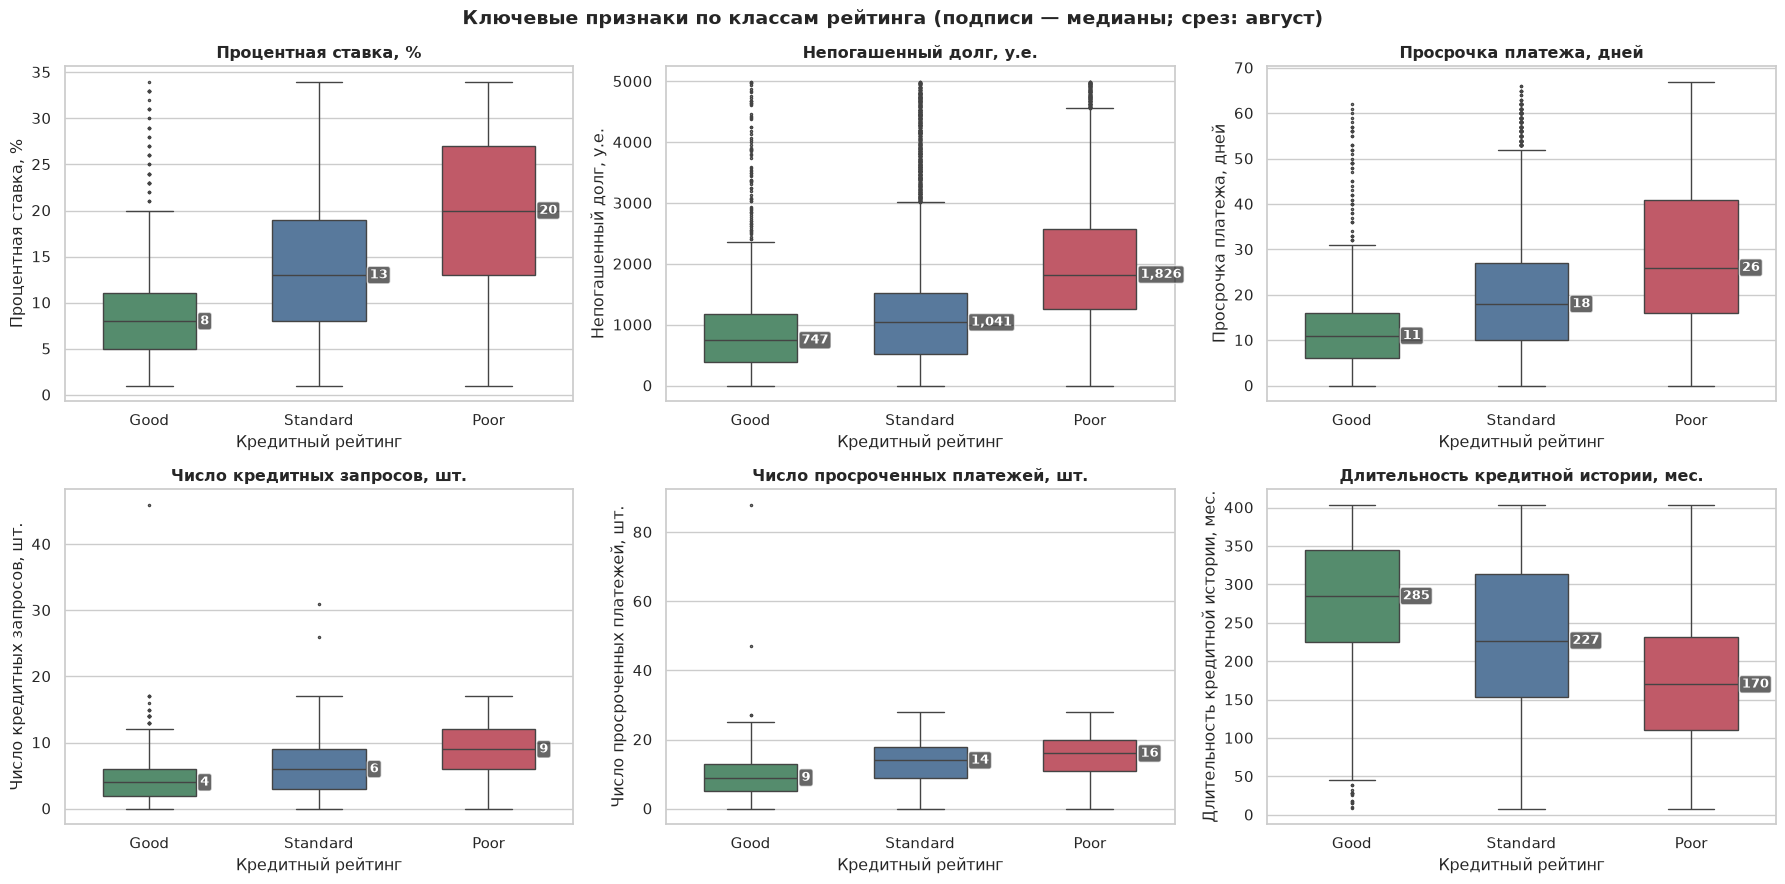

In [23]:
BOX_FEATURES = ["Interest_Rate", "Outstanding_Debt", "Delay_from_due_date",
                "Num_Credit_Inquiries", "Num_of_Delayed_Payment", "Credit_History_Months"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, column in zip(axes.flat, BOX_FEATURES):
    sns.boxplot(data=snapshot, x="Credit_Score", y=column, hue="Credit_Score", order=SCORE_ORDER,
                palette=SCORE_COLORS, legend=False, dodge=False, fliersize=1.5, width=0.55, ax=ax)
    medians = snapshot.groupby("Credit_Score", observed=True)[column].median().reindex(SCORE_ORDER)
    for i, value in enumerate(medians):
        ax.text(i + 0.3, value, f"{value:,.0f}", ha="left", va="center", fontsize=9,
                fontweight="bold", color="white",
                bbox={"boxstyle": "round,pad=0.2", "facecolor": "black", "alpha": 0.6})
    ax.set_title(f"{label(column)}")
    ax.set_xlabel("Кредитный рейтинг")
    ax.set_ylabel(label(column))
fig.suptitle("Ключевые признаки по классам рейтинга (подписи — медианы; срез: август)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Что видно

Медианы во всех шести признаках изменяются монотонно `Good` → `Standard` → `Poor`. У ставки и числа
запросов ящики `Good` и `Poor` почти не перекрываются. `Standard` – промежуточный класс, его модели
будет сложнее всего отличить.

## 24. Violin plot

«Скрипка» – боксплот, к которому добавлена форма распределения: ширина фигуры показывает,
как много наблюдений при данном значении. `inner="quartile"` – линии квартилей внутри,
`cut=0` – фигура не выходит за реальные минимум и максимум.

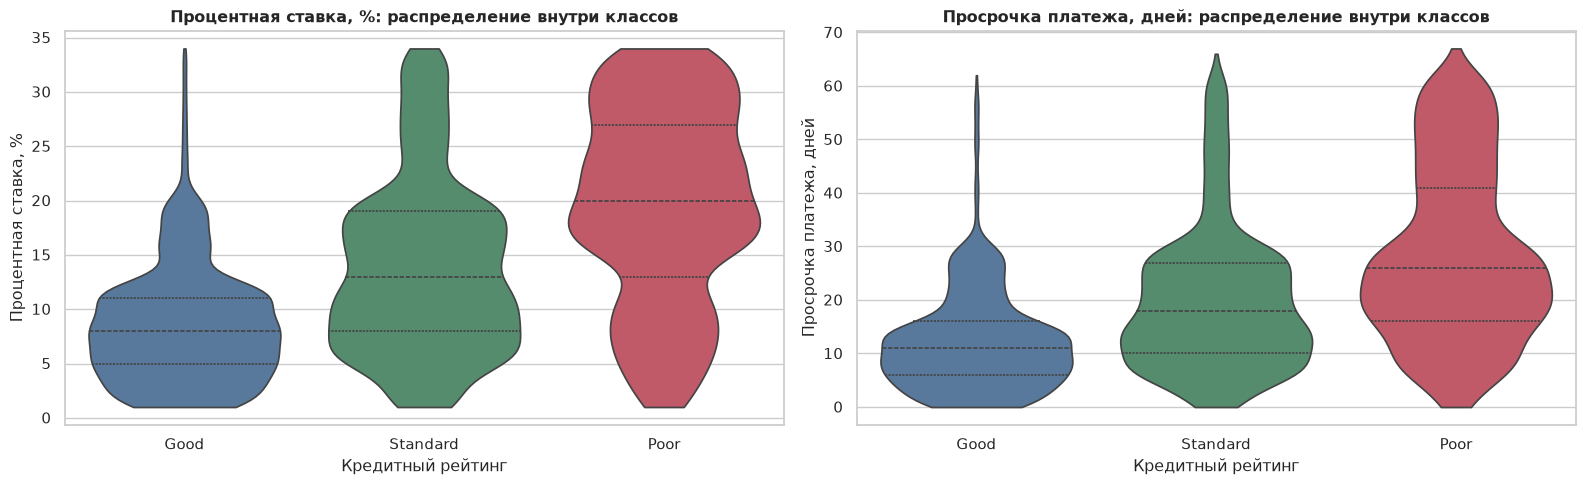

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, column in zip(axes, ["Interest_Rate", "Delay_from_due_date"]):
    sns.violinplot(data=snapshot, x="Credit_Score", y=column, hue="Credit_Score", order=SCORE_ORDER,
                   palette=SCORE_COLORS, legend=False, dodge=False, inner="quartile", cut=0, ax=ax)
    ax.set_title(f"{label(column)}: распределение внутри классов")
    ax.set_xlabel("Кредитный рейтинг")
    ax.set_ylabel(label(column))
plt.tight_layout()
plt.show()

### Что видно

У `Good` ставка сосредоточена в узком пике около 5–8%, у `Poor` – широкое плоское распределение 15–34%.
Просрочка у `Good` в основном 0–15 дней, у `Poor` растянута до 60+ дней. Боксплот этой разницы
в форме не показывает.

## 25. Boxen plot для тяжёлого хвоста

У доли EMI очень длинный хвост. Обычный боксплот превратил бы его в облако точек. Boxen plot
(letter-value plot) рисует больше квантилей – вложенные ящики для 50%, 75%, 87,5% … наблюдений.
Ось Y логарифмическая. Здесь используем все строки: это описание формы, а не тест.

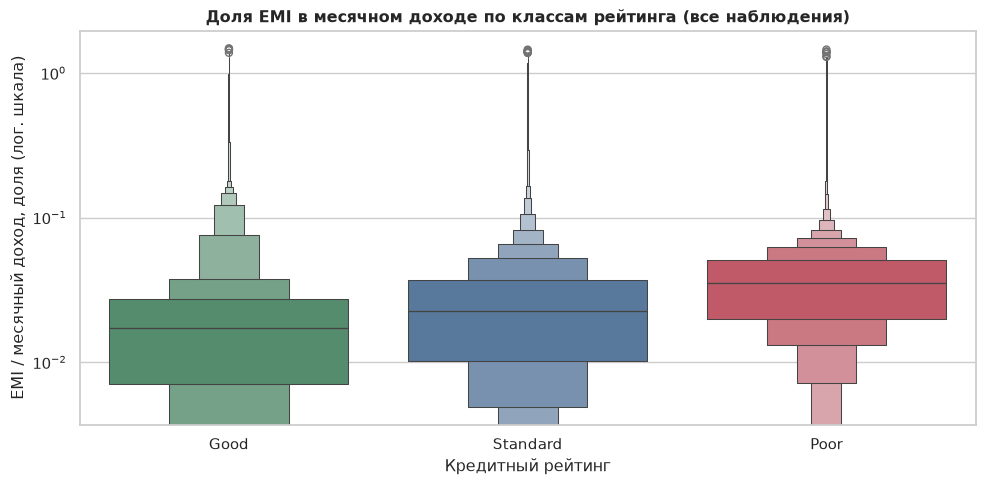

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxenplot(data=df, x="Credit_Score", y="EMI_to_Monthly_Income", hue="Credit_Score",
              order=SCORE_ORDER, palette=SCORE_COLORS, legend=False, dodge=False, ax=ax)
ax.set_yscale("log")
ax.set_title("Доля EMI в месячном доходе по классам рейтинга (все наблюдения)")
ax.set_xlabel("Кредитный рейтинг")
ax.set_ylabel("EMI / месячный доход, доля (лог. шкала)")
plt.tight_layout()
plt.show()

### Что видно

Медиана доли EMI у `Poor` выше, но ящики классов сильно перекрываются. Это наглядное подтверждение
малого эффекта по H5 (ε² = 0,044).

## 26. Диаграммы рассеяния

Каждая точка – клиент; по осям – два признака, цвет – класс. `snapshot.sample(4000, random_state=42)` –
случайные 4 000 клиентов из среза: при 12 500 точки слились бы в сплошное пятно. `random_state`
фиксирует выборку, чтобы при перезапуске получалась та же картинка. `alpha=0.55` – полупрозрачность,
плотные области выглядят темнее.

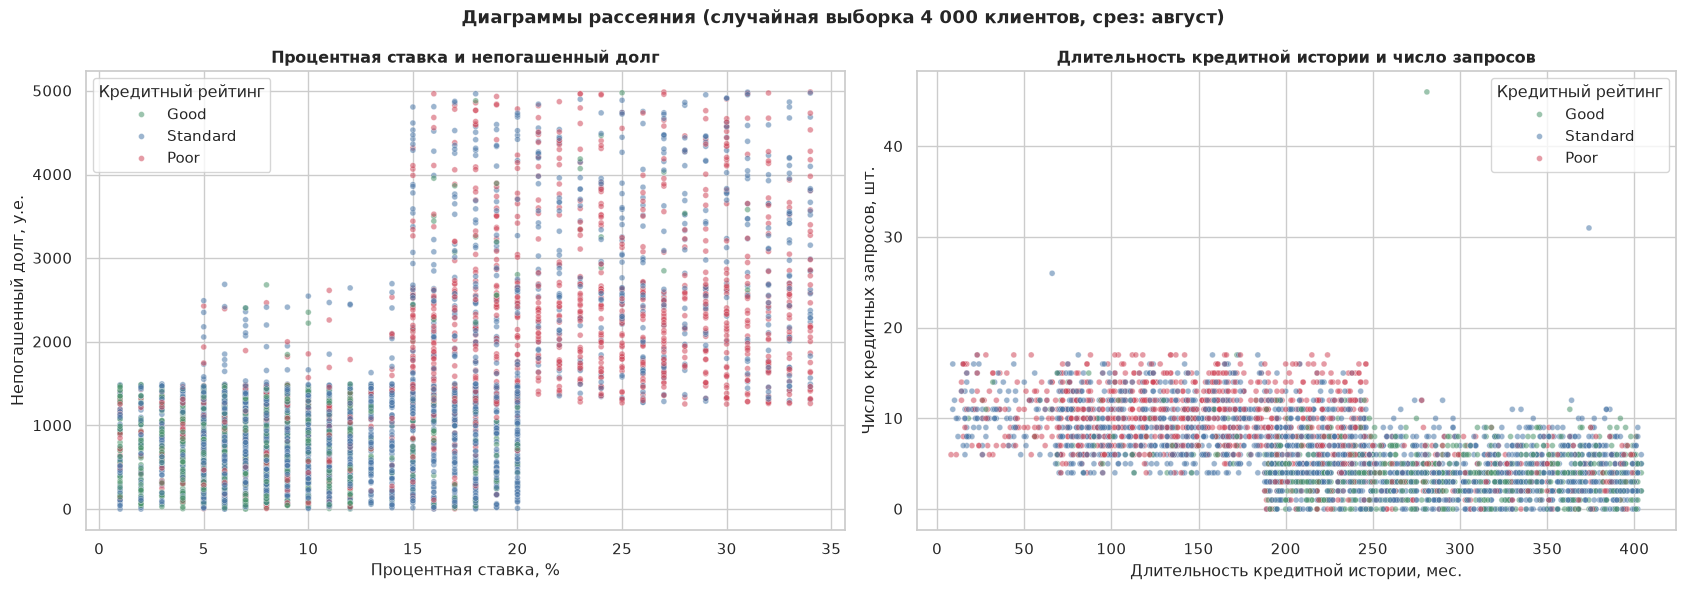

In [26]:
sample = snapshot.sample(4000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.scatterplot(data=sample, x="Interest_Rate", y="Outstanding_Debt", hue="Credit_Score",
                hue_order=SCORE_ORDER, palette=SCORE_COLORS, alpha=0.55, s=18, ax=axes[0])
axes[0].set_title("Процентная ставка и непогашенный долг")
axes[0].set_xlabel(label("Interest_Rate"))
axes[0].set_ylabel(label("Outstanding_Debt"))
axes[0].legend(title="Кредитный рейтинг")

sns.scatterplot(data=sample, x="Credit_History_Months", y="Num_Credit_Inquiries", hue="Credit_Score",
                hue_order=SCORE_ORDER, palette=SCORE_COLORS, alpha=0.55, s=18, ax=axes[1])
axes[1].set_title("Длительность кредитной истории и число запросов")
axes[1].set_xlabel(label("Credit_History_Months"))
axes[1].set_ylabel(label("Num_Credit_Inquiries"))
axes[1].legend(title="Кредитный рейтинг")
fig.suptitle("Диаграммы рассеяния (случайная выборка 4 000 клиентов, срез: август)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### Что видно

- Ставка × долг – ступенчатая связь: при ставке до 14% долг почти не выше ~1 500 у.е. (преобладают
  `Good`/`Standard`), выше 20% – долг не ниже ~1 300 у.е. (преобладает `Poor`). Резкие «блоки» –
  ещё один признак синтетической генерации.
- История × запросы – отрицательная связь: при длинной истории запросов мало, и `Poor` реже.
- В средней зоне классы перемешаны – двух признаков недостаточно, нужна многомерная модель.

## 27. Категориальные признаки

Для каждого категориального признака – доля классов рейтинга внутри каждой категории (каждая полоса = 100%).
Полосы отсортированы по доле `Poor`. В заголовок подставлен V Крамера из таблицы тестов (`results`).

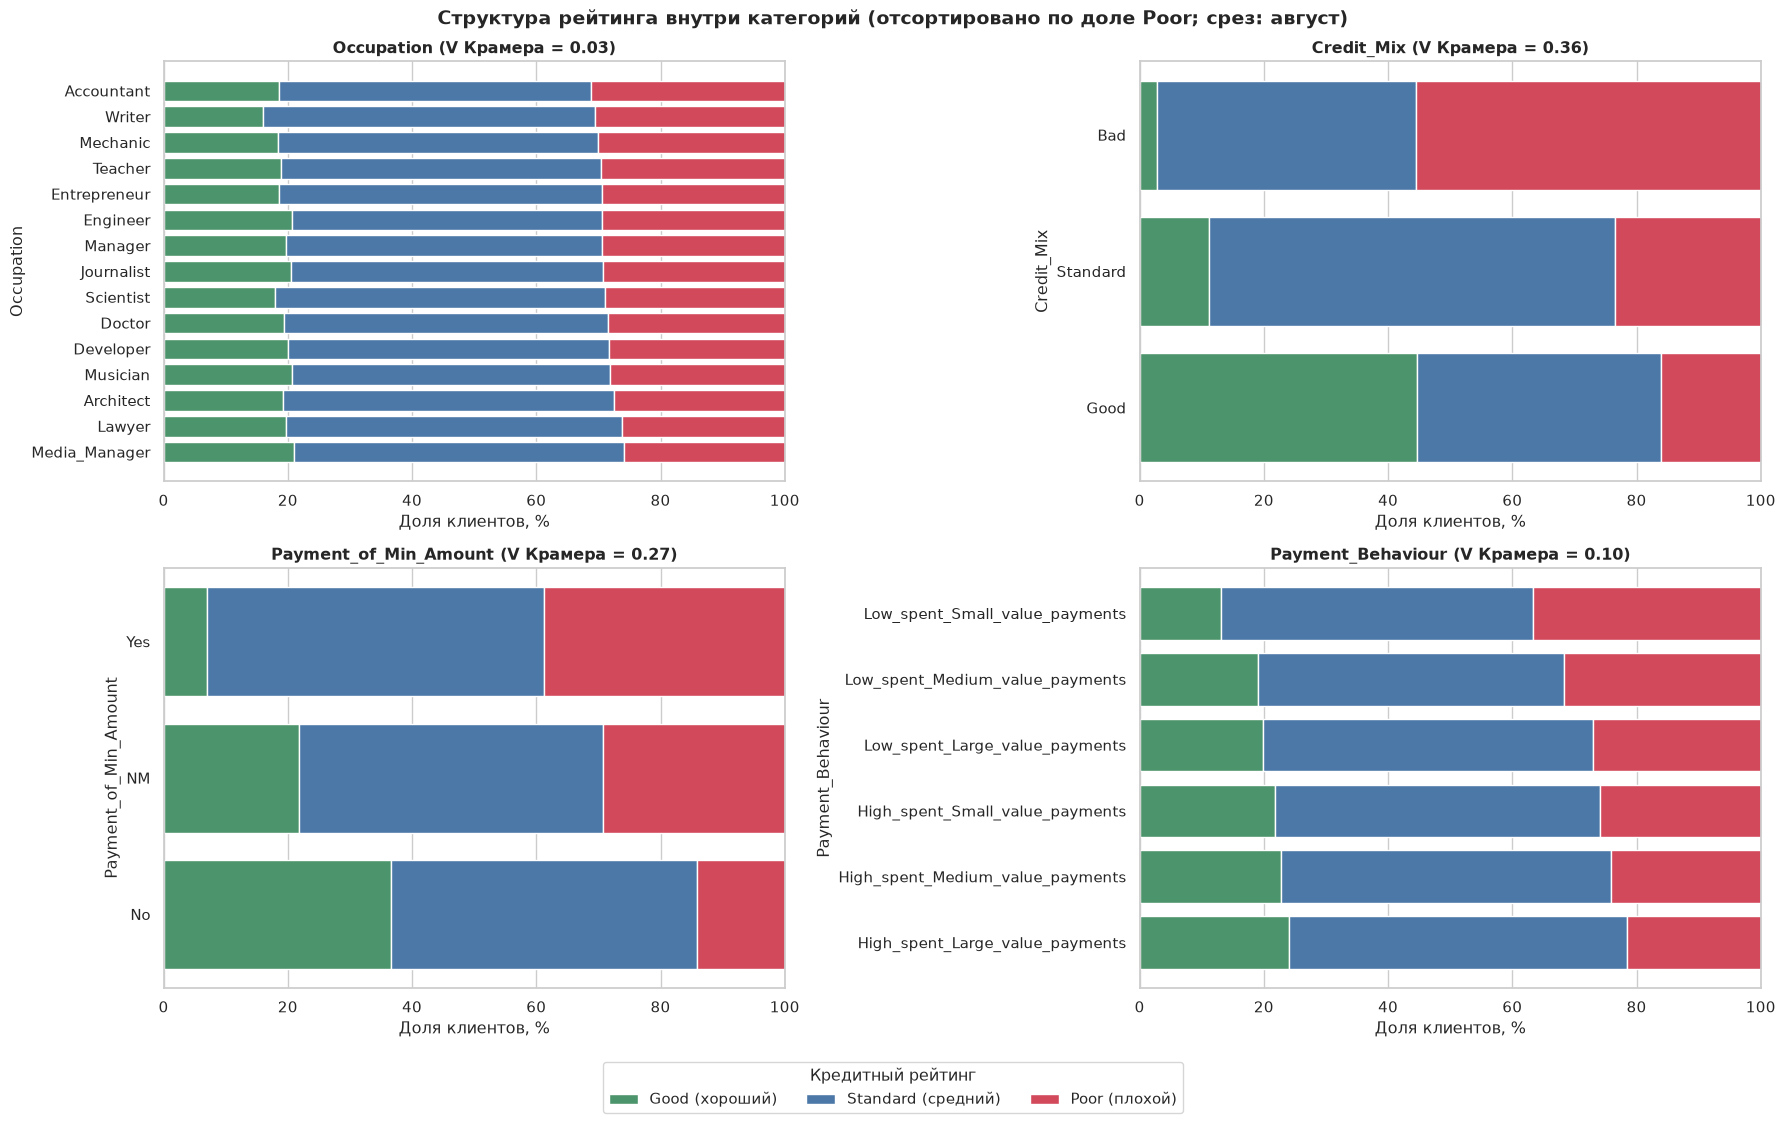

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, column in zip(axes.flat, CATEGORICAL):
    share = (pd.crosstab(snapshot[column], snapshot["Credit_Score"], normalize="index")
             .reindex(columns=SCORE_ORDER).mul(100).sort_values("Poor"))
    left = np.zeros(len(share))
    for score in SCORE_ORDER:
        ax.barh(share.index, share[score], left=left, color=SCORE_COLORS[score],
                label=SCORE_RU[score], edgecolor="white")
        left += share[score].values
    v = results.loc[results["признак"] == column, "эффект"].iloc[0]
    ax.set_title(f"{column} (V Крамера = {v:.2f})")
    ax.set_xlabel("Доля клиентов, %")
    ax.set_ylabel(column)
    ax.set_xlim(0, 100)
handles, labels_ = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels_, title="Кредитный рейтинг", loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Структура рейтинга внутри категорий (отсортировано по доле Poor; срез: август)",
             fontsize=14, fontweight="bold")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

### Что видно

`Credit_Mix` (V = 0,36) и `Payment_of_Min_Amount` (V = 0,27) дают резко разную структуру по категориям.
У `Payment_Behaviour` (V = 0,10) различия слабые. У `Occupation` (V = 0,03) полосы почти одинаковы для всех
15 профессий – связи нет. Категория `NM` (не указано) у `Payment_of_Min_Amount` по доле `Poor` лежит между
`No` и `Yes`, поэтому решение ЛР1 оставить её отдельной категорией оправдано.

## 28. Heatmap взаимодействия двух факторов

`pivot_table(index="Credit_Mix", columns="Delay_Band", values="is_poor", aggfunc="mean")` – доля `Poor`
в каждой комбинации структуры кредитов и длительности просрочки. `is_poor` – True/False,
поэтому среднее равно доле. Вторая сводная таблица `counts` – число клиентов в клетке;
подпись `annotations` объединяет долю и n.

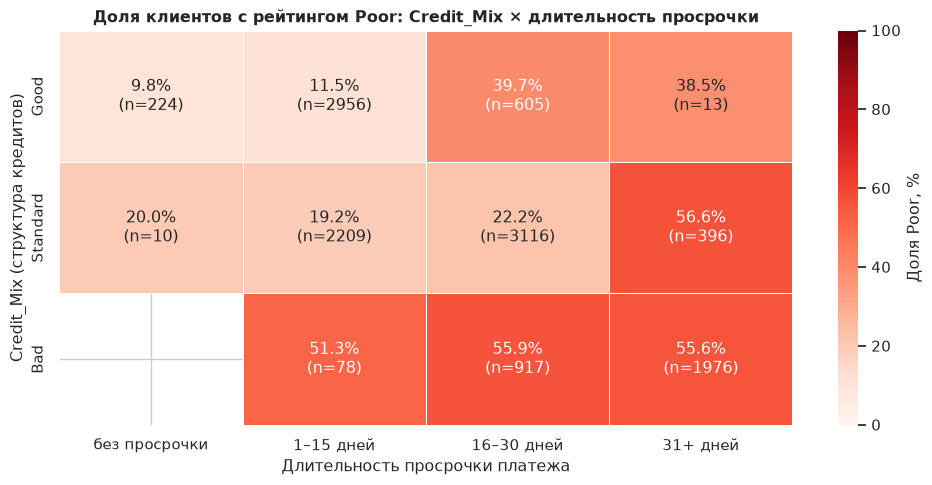

In [28]:
pivot = (snapshot.assign(is_poor=snapshot["Credit_Score"].eq("Poor"))
         .pivot_table(index="Credit_Mix", columns="Delay_Band", values="is_poor",
                      aggfunc="mean", observed=True)
         .reindex(index=["Good", "Standard", "Bad"],
                  columns=["без просрочки", "1–15 дней", "16–30 дней", "31+ дней"]) * 100)
counts = (snapshot.pivot_table(index="Credit_Mix", columns="Delay_Band", values="ID",
                               aggfunc="count", observed=True)
          .reindex(index=pivot.index, columns=pivot.columns))
annotations = pivot.round(1).astype(str) + "%\n(n=" + counts.fillna(0).astype(int).astype(str) + ")"

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(pivot, annot=annotations, fmt="", cmap="Reds", vmin=0, vmax=100, linewidths=0.5,
            cbar_kws={"label": "Доля Poor, %"}, ax=ax)
ax.set_title("Доля клиентов с рейтингом Poor: Credit_Mix × длительность просрочки")
ax.set_xlabel("Длительность просрочки платежа")
ax.set_ylabel("Credit_Mix (структура кредитов)")
plt.tight_layout()
plt.show()

### Что видно

Влияние одного фактора зависит от другого: при `Credit_Mix = Good` доля `Poor` низкая, пока просрочка
до 15 дней, и резко растёт при 16+ днях; при `Bad` она высокая при любой просрочке.
Клетка `Bad` × «без просрочки» пуста (таких клиентов нет), а в `Good` × «31+ дней» мало клиентов –
оценку там считать ненадёжной. Взаимодействия – аргумент в пользу деревьев и ансамблей в ЛР3.

## 29. Итоговая таблица гипотез и сохранение результатов

Функция `fmt_kw` достаёт из `results` ε² и медианы классов для признака и форматирует строку.
Для доли EMI медианы переводятся в проценты (`percent=True`): иначе 0,019 / 0,024 / 0,034 при одном знаке
округлились бы до 0,0.

Таблица `hypotheses` собирается из рассчитанных значений, а не вписывается вручную: при изменении данных
она обновится сама.

`to_csv` сохраняет 12 итоговых таблиц в `eda-visualization/results`. Графики остаются в ноутбуке.

In [29]:
def fmt_kw(column, percent=False):
    row = results.set_index("признак").loc[column]
    values = [row[s] * 100 if percent else row[s] for s in SCORE_ORDER]
    unit = "%" if percent else ""
    return (f"ε² = {row['эффект']:.3f}; медианы Good / Standard / Poor: "
            + " / ".join(f"{v:,.1f}{unit}" for v in values))

mix_v = results.set_index("признак").loc["Credit_Mix", "эффект"]
hypotheses = pd.DataFrame({
    "Гипотеза": [
        "Долг связан с худшим рейтингом", "Просрочка связана с худшим рейтингом",
        "Высокая ставка чаще у Poor", "Credit_Mix = Bad связан с худшим рейтингом",
        "Частые запросы связаны с худшим рейтингом", "Доля EMI в доходе связана с худшим рейтингом",
    ],
    "Результат": [
        "Подтверждается", "Подтверждается", "Подтверждается", "Подтверждается",
        "Подтверждается", "Подтверждается частично: эффект малый",
    ],
    "Основание": [
        fmt_kw("Outstanding_Debt"), fmt_kw("Delay_from_due_date"), fmt_kw("Interest_Rate"),
        f"V Крамера = {mix_v:.3f}; доля Poor при Bad {mix_table.loc['Bad', 'Poor']:.1f}%, OR = {odds_ratio:.2f}",
        fmt_kw("Num_Credit_Inquiries"), fmt_kw("EMI_to_Monthly_Income", percent=True),
    ],
}, index=["H1", "H1", "H2", "H3", "H4", "H5"])
hypotheses.index.name = "№"
display(hypotheses)

descriptive.to_csv(RESULTS / "descriptive_stats.csv", index_label="Признак")
normality.to_csv(RESULTS / "normality.csv")
outliers.to_csv(RESULTS / "outliers_iqr.csv", index_label="Признак")
corr.to_csv(RESULTS / "correlation_matrix.csv", index_label="Признак")
target_corr.rename("Спирмен с рейтингом").sort_values(key=abs, ascending=False).to_csv(
    RESULTS / "score_correlations.csv", index_label="Признак")
results.to_csv(RESULTS / "hypothesis_tests.csv", index=False)
ranking.to_csv(RESULTS / "factor_ranking.csv", index_label="Место")
month_share.to_csv(RESULTS / "score_by_month.csv", index_label="Месяц")
monthly_medians.to_csv(RESULTS / "medians_by_month.csv", index_label="Месяц")
transition_matrix.to_csv(RESULTS / "score_transitions.csv", index_label="Рейтинг сейчас")
season_stats.to_csv(RESULTS / "score_by_season.csv", index_label="Сезон")
hypotheses.to_csv(RESULTS / "hypotheses.csv")
print("Сохранено таблиц:", len(list(RESULTS.glob("*.csv"))))

,Гипотеза,Результат,Основание
№,,,
H1,Долг связан с худшим рейтингом,Подтверждается,ε² = 0.153; медианы Good / Standard / Poor: 74...
H1,Просрочка связана с худшим рейтингом,Подтверждается,ε² = 0.146; медианы Good / Standard / Poor: 11...
H2,Высокая ставка чаще у Poor,Подтверждается,ε² = 0.181; медианы Good / Standard / Poor: 8....
H3,Credit_Mix = Bad связан с худшим рейтингом,Подтверждается,"V Крамера = 0.361; доля Poor при Bad 55.6%, OR..."
H4,Частые запросы связаны с худшим рейтингом,Подтверждается,ε² = 0.143; медианы Good / Standard / Poor: 4....
H5,Доля EMI в доходе связана с худшим рейтингом,Подтверждается частично: эффект малый,ε² = 0.044; медианы Good / Standard / Poor: 1....


Сохранено таблиц: 12


### Вывод

1. Ни один признак не распределён нормально; денежные признаки асимметричны – используем медианы и ранговые методы.
2. Выбросы по IQR – естественный хвост и информативны (среди них больше `Poor`), поэтому сохранены.
3. Сильнее всего с рейтингом связаны ставка, долг, просрочка, число запросов и `Credit_Mix`.
4. H1–H4 подтверждаются с большим или умеренным эффектом, H5 – частично (эффект малый). Профессия не связана с рейтингом.
5. Сезонности нет; есть ступенька в апреле и рост числа запросов. Рейтинг клиента стабилен, поэтому в ЛР3
   разбиение – по клиентам.

Ограничения: данные частично синтетические, связи описательные и не доказывают причинность.